<a href="https://colab.research.google.com/github/mshitie/quantitative_XAI/blob/main/BUSBRA_Uncertainty_Explainability_Framework_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Uncertainty-Calibrated Explainable CNN Framework for Reliable Breast Ultrasound Classification (BUS-BRA)

**Central question:** *Can a CNN's predictions be trusted?* Architecture comparison is the experimental foundation; the main scientific focus is the **relationship between predictive uncertainty and explanation reliability**.

**Pipeline.** The results folder `/content/BUSBRA_UQ_XAI_results/` contains only manuscript-relevant PNG figures and CSV tables. Model checkpoints, logits and long per-image tables are written to `/content/work_busbra/` (not zipped, not downloaded):

| Section | What it does | Saved to |
|---|---|---|
| 0 | Dataset location, imports, configuration | – |
| 1 | BUS-BRA loading, patient-level split, EDA figures | `figures/`, `tables/` |
| 2 | Six CNNs (ResNet50, DenseNet121, EfficientNet-B0, MobileNetV3-L, ConvNeXt-T, InceptionV3), identical protocol, 3 seeds each (deep ensemble) | (checkpoints kept outside the results folder) |
| 3 | Classification metrics (+ bootstrap CIs), confusion matrices, ROC curves | |
| 4 | Uncertainty: MC Dropout + Deep Ensembles; entropy, mutual information, variance; temperature scaling; ECE / Brier / NLL; reliability diagrams | |
| 5 | Selective prediction, risk-coverage analysis | |
| 6 | Robustness to perturbations (noise, speckle, blur, contrast, JPEG) | |
| 7 | Grad-CAM: stability across stochastic passes and ensemble members, agreement with lesion masks | |
| 8 | **Uncertainty vs. explanation reliability** (core analysis) | |
| 9 | SHAP explanations and their stability | |
| 10 | Ablation study (uncertainty / calibration / explanation gating) | |
| 11 | Computational complexity | |
| 12 | Final ranking: *is the most accurate architecture also the most trustworthy?* | |

**Notes / caveats**
* BUS-BRA has 1,875 images (1,064 patients; benign/malignant only) and the held-out test fold is ~380 images, so confidence intervals are wide. Per-image statistics are reported with bootstrap CIs.
* The split is patient-level (folds from the official 5-fold CSV), so left/right/single views of one patient never cross splits.
* Temperature scaling is fit on the validation split only; the test split is never used for fitting anything.
* Novelty of the proposed contribution must still be verified against the latest literature before it is claimed.

Set `CFG.QUICK = True` in section 0 for a fast smoke test (2 architectures, 3 epochs).

## 0. Setup: Dataset location, imports, configuration

In [5]:
import zipfile
import os

zip_path = "/content/BUSBRA.zip"
extract_path = "/content/BUSBRA"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Files and folders:", os.listdir(extract_path))

Dataset extracted successfully!
Files and folders: ['BUSBRA']


In [ ]:
!pip install -q shap
from pathlib import Path
BUSBRA = Path('/content/BUSBRA')
assert BUSBRA.exists(), "Upload / unzip the dataset to /content/BUSBRA first"
need = ['bus_data.csv', '5-fold-cv.csv']          # metadata + official patient-level folds (10-fold-cv.csv is optional)
for n in need:
    hit = next(BUSBRA.rglob(n), None)
    print(f'{n:14s}', 'found: ' + str(hit) if hit else 'MISSING (upload it into /content/BUSBRA)')
print('images:', sum(1 for p in BUSBRA.rglob('bus_*.png')), '| masks:', sum(1 for p in BUSBRA.rglob('mask_*.png')))


In [7]:
import os, sys, glob, json, time, math, random, shutil, warnings, copy, traceback, platform, io
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models, transforms as T
import torchvision.transforms.functional as TF
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, roc_auc_score, roc_curve,
                             precision_recall_fscore_support, f1_score)
from scipy import stats, ndimage
from scipy.special import softmax
from scipy.optimize import minimize_scalar
from IPython.display import display

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'axes.titlesize': 11, 'axes.labelsize': 10})


class CFG:
    SEED = 42
    IMG = 224                # identical input size for every architecture (fair protocol)
    BATCH = 32
    EPOCHS = 25
    PATIENCE = 7             # early stopping on validation loss
    LR = 1e-4
    WD = 1e-4
    DROPOUT = 0.3            # dropout before the classifier (used for MC Dropout)
    MC_T = 30                # MC Dropout forward passes
    CAM_T = 10               # stochastic Grad-CAM passes
    ROB_T = 15               # MC passes in robustness experiments
    ENS_M = 3                # deep-ensemble size (independent seeds)
    N_BINS = 15              # ECE bins
    BOOT = 1000              # bootstrap resamples
    SHAP_N = 16              # images explained with SHAP
    SHAP_NS = 40             # SHAP expected-gradients samples
    SHAP_REP = 3             # repeated SHAP runs for stability
    ARCHS = ['ResNet50', 'DenseNet121', 'EfficientNet-B0', 'MobileNetV3-Large', 'ConvNeXt-Tiny', 'InceptionV3']
    CLASSES = ['benign', 'malignant']   # BUS-BRA: benign vs malignant
    QUICK = False            # <- set True for a fast smoke test
    SAVE_TO_DRIVE = False    # <- set True to copy the results folder to Google Drive at the end
    DRIVE_DIR = '/content/drive/MyDrive/BUSBRA_UQ_XAI_results'

if CFG.QUICK:
    CFG.EPOCHS, CFG.ENS_M, CFG.MC_T, CFG.CAM_T, CFG.ROB_T = 3, 2, 10, 4, 5
    CFG.ARCHS, CFG.BOOT, CFG.SHAP_N, CFG.SHAP_NS, CFG.SHAP_REP = CFG.ARCHS[:2], 200, 6, 10, 2

ARCHS, CLASSES, NC = CFG.ARCHS, CFG.CLASSES, len(CFG.CLASSES)
PAL = dict(zip(ARCHS, sns.color_palette('tab10', len(ARCHS))))

_sfx = '_quick' if CFG.QUICK else ''       # quick smoke-test never mixes with the full run
OUT = Path('/content/BUSBRA_UQ_XAI_results' + _sfx)      # manuscript-ready outputs ONLY (figures + tables) -> zipped / downloaded
WORK = Path('/content/work_busbra' + _sfx)                     # checkpoints, logits, long/per-image tables -> NOT part of the results
FIG, TAB = OUT / 'figures', OUT / 'tables'
MOD, LOG, EXTRA = WORK / 'models', WORK / 'logs', WORK / 'extra'
for d in (FIG, TAB, MOD, LOG, EXTRA):
    d.mkdir(parents=True, exist_ok=True)

# Only these figures / tables are written to the results folder (the rest is computed and used, but not saved there)
KEEP_FIG = ('F0a_', 'F0c_', 'F2_', 'F3_', 'F4_', 'F5_', 'F6_', 'F7_', 'F9_', 'F10_', 'F12_', 'F13_', 'F14_', 'F16_', 'F17_', 'F18_',
            'F19_', 'F20_', 'F21_', 'F22_', 'F23_', 'F26_', 'F29_', 'F30_', 'F31_', 'F33_', 'F34_', 'F36_', 'F37_', 'F38_')
KEEP_TAB = {'T0_dataset_summary', 'T0c_metadata_summary', 'T0d_subgroup_performance', 'T1_Deterministic', 'T1_Deep_Ensemble_plus_TS', 'T2_calibration_by_variant', 'T3_bootstrap_CI',
            'T4_uncertainty_vs_errors_ensemble_TS', 'T5_selective_prediction_ensemble_TS', 'T7_robustness_summary', 'T9_explanation_summary',
            'T10_spearman_stability_ensemble_unc', 'T11a_tercile_stab_ens_by_entropy_ens', 'T12_explanation_correct_vs_wrong',
            'T14_shap_uncertainty_spearman', 'T15_ablation_mean_std', 'T16_computational_complexity', 'T17_final_summary', 'T18_rankings'}

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = device.type == 'cuda'
torch.backends.cudnn.benchmark = True


def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


set_seed(CFG.SEED)


# ---------- saving helpers ----------
def savefig(name, fig=None, show=True):
    """PNG only (300 dpi). Figures not in KEEP_FIG are closed without saving."""
    fig = fig or plt.gcf()
    try:
        fig.tight_layout()
    except Exception:
        pass
    if name.startswith(KEEP_FIG):
        fig.savefig(FIG / f'{name}.png', bbox_inches='tight')
        print(f'[saved figure] figures/{name}.png')
        if show:
            plt.show()
    plt.close(fig)


def save_table(df, name, index=True, show=True, png=True):
    """CSV only. Tables not in KEEP_TAB go to the work folder (not part of the results)."""
    keep = name in KEEP_TAB
    df.to_csv((TAB if keep else EXTRA) / f'{name}.csv', index=index, float_format='%.5f')
    if keep:
        print(f'[saved table] tables/{name}.csv')
        if show:
            display(df.round(4))


def grid(n, ncols=3, w=5, h=4.2, **kw):
    nr = int(np.ceil(n / ncols))
    fig, axs = plt.subplots(nr, ncols, figsize=(w * ncols, h * nr), **kw)
    axs = np.atleast_1d(axs).ravel()
    for a in axs[n:]:
        a.axis('off')
    return fig, axs[:n]


env = dict(python=platform.python_version(), torch=torch.__version__, torchvision=torchvision.__version__,
           device=str(device), gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None)
json.dump({'env': env, 'cfg': {k: v for k, v in vars(CFG).items() if not k.startswith('_')}},
          open(OUT / 'config_and_env.json', 'w'), indent=2, default=str)
print(env)

{'python': '3.13.16', 'torch': '2.14.1+cu130', 'torchvision': '0.29.1+cu130', 'device': 'cuda', 'gpu': 'Tesla T4'}


## 1. Data: BUS-BRA loading, patient-level split, exploratory figures

1875 images, 1875 masks found
ground truth source: {'mask': 1875}


  0%|          | 0/1127 [00:00<?, ?it/s]

  0%|          | 0/365 [00:00<?, ?it/s]

  0%|          | 0/383 [00:00<?, ?it/s]

{'train': (1127, 3, 224, 224), 'val': (365, 3, 224, 224), 'test': (383, 3, 224, 224)}
[saved table] tables/T0_dataset_summary.csv


cls,benign,malignant,total,patients
split,,,,
test,262,121,383,212
train,760,367,1127,638
val,246,119,365,214
all,1268,607,1875,1064


[saved table] tables/T0c_metadata_summary.csv


cls                                   benign  malignant
factor  level                                          
BI-RADS 2                                552         10
        3                                432         31
        4                                280        413
        5                                  4        153
Device  GE Logiq 5 @10-12MHz             566        243
        GE Logiq 7 @10-14MHz             617        285
        Toshiba Aplio 300 @12-14 MHz      71         68
        U-Systems @10-14MHz               14         11
View    left                             546        265
        right                            546        265
        single                           176         77

[saved figure] figures/F0a_dataset_overview.png


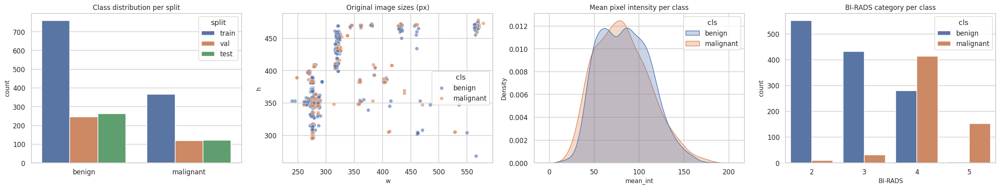

[saved figure] figures/F0c_sample_images.png


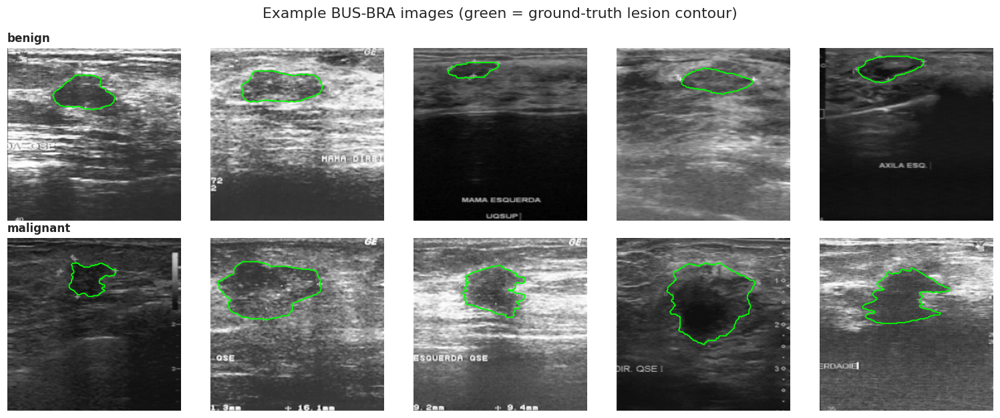

In [8]:
# ---------- BUS-BRA dataframe (built from bus_data.csv) ----------
# images: bus_XXXX-l/-r/-s.png   masks: mask_XXXX-l/-r/-s.png   (anywhere below /content/BUSBRA)
IMG_EXT = ('.png', '.jpg', '.jpeg')
img_files  = {p.stem: p for p in BUSBRA.rglob('*') if p.suffix.lower() in IMG_EXT and p.stem.startswith('bus_')}
mask_files = {p.stem: p for p in BUSBRA.rglob('*') if p.suffix.lower() in IMG_EXT and p.stem.startswith('mask_')}
print(f'{len(img_files)} images, {len(mask_files)} masks found')

meta_path = next(BUSBRA.rglob('bus_data.csv'), None)
assert meta_path is not None, 'Put bus_data.csv inside /content/BUSBRA (or upload it there)'
meta = pd.read_csv(meta_path)
missing_img = sorted(set(meta.ID) - set(img_files))
if missing_img:
    print(f'[warn] {len(missing_img)} rows of bus_data.csv have no image file (dropped), e.g. {missing_img[:3]}')
meta = meta[meta.ID.isin(img_files)].reset_index(drop=True)

df = pd.DataFrame(dict(
    id=meta.ID, case=meta.Case, cls=meta.Pathology, label=meta.Pathology.map({c: i for i, c in enumerate(CLASSES)}),
    histology=meta.Histology, birads=meta.BIRADS, device=meta.Device, side=meta.Side,
    bbox=meta.BBOX.apply(lambda s: [int(v) for v in json.loads(s)]),          # [x, y, w, h] in original pixels
    path=meta.ID.map(lambda i: str(img_files[i])),
    masks=meta.ID.map(lambda i: [str(mask_files[i.replace('bus_', 'mask_')])] if i.replace('bus_', 'mask_') in mask_files else []),
    w=meta.Width, h=meta.Height))
assert df.label.notna().all(), f'unexpected Pathology values: {sorted(meta.Pathology.unique())}'
df['label'] = df.label.astype(int)
df['mask_src'] = np.where(df.masks.str.len() > 0, 'mask', 'bbox')               # no mask file -> lesion bounding box is used as ground truth
print('ground truth source:', df.mask_src.value_counts().to_dict())

# --- patient-level split: official 5-fold CSV (train = folds 1-3, val = fold 4, test = fold 5);
#     fallback: stratified split grouped by Case. Either way no patient appears in two splits.
fold_csv = next(BUSBRA.rglob('5-fold-cv.csv'), None)
if fold_csv is not None:
    kf = pd.read_csv(fold_csv).set_index('ID').kFold
    df['fold'] = df.id.map(kf)
    assert df.fold.notna().all(), 'some images are missing from 5-fold-cv.csv'
else:
    from sklearn.model_selection import StratifiedGroupKFold
    fo = np.zeros(len(df), int)
    for k, (_, te) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=CFG.SEED).split(df, df.label, df.case)):
        fo[te] = k + 1
    df['fold'] = fo
df['fold'] = df.fold.astype(int)
df['split'] = df.fold.map(lambda k: 'train' if k <= 3 else 'val' if k == 4 else 'test')
sp_cases = {s: set(df[df.split == s].case) for s in ('train', 'val', 'test')}
assert not (sp_cases['train'] & sp_cases['val'] or sp_cases['train'] & sp_cases['test'] or sp_cases['val'] & sp_cases['test']), 'patient leakage between splits'
tr_idx, va_idx, te_idx = [np.where(df.split == s)[0] for s in ('train', 'val', 'test')]
df.drop(columns=['masks']).to_csv(TAB / 'split_assignment.csv', index=False)


def load_rgb(p):
    return np.asarray(Image.open(p).convert('RGB').resize((CFG.IMG, CFG.IMG), Image.BILINEAR))


def load_mask(row):
    """Ground-truth lesion mask at IMG x IMG; falls back to the BBOX rectangle when the mask file is missing/empty."""
    m = np.zeros((CFG.IMG, CFG.IMG), bool)
    for p in row.masks:
        m |= np.asarray(Image.open(p).convert('L').resize((CFG.IMG, CFG.IMG), Image.NEAREST)) > 0
    if not m.any():
        W, H = Image.open(row.path).size; x, y, bw, bh = row.bbox
        m[int(round(y / H * CFG.IMG)):int(round((y + bh) / H * CFG.IMG)), int(round(x / W * CFG.IMG)):int(round((x + bw) / W * CFG.IMG))] = True
    return m


def build(ids):
    X = torch.from_numpy(np.stack([load_rgb(df.path.iloc[i]) for i in tqdm(ids, leave=False)])).permute(0, 3, 1, 2).contiguous()
    M = torch.from_numpy(np.stack([load_mask(df.iloc[i]) for i in ids]))
    y = torch.tensor(df.label.values[ids])
    return X, M, y


Xtr, Mtr, ytr = build(tr_idx)
Xva, Mva, yva = build(va_idx)
Xte, Mte, yte = build(te_idx)
Xtr_f, Xva_f, Xte_f = None, Xva.float() / 255., Xte.float() / 255.
yva_np, yte_np = yva.numpy(), yte.numpy()
print({k: tuple(v.shape) for k, v in dict(train=Xtr, val=Xva, test=Xte).items()})
for k, M in dict(train=Mtr, val=Mva, test=Mte).items():
    assert M.reshape(len(M), -1).any(1).all(), f'{k}: some lesion masks are empty'

df['mean_int'] = np.nan
for ids, X in ((tr_idx, Xtr), (va_idx, Xva), (te_idx, Xte)):
    df.loc[df.index[ids], 'mean_int'] = X.mean((1, 2, 3), dtype=torch.float32).numpy()

summ = pd.crosstab(df.split, df.cls)[CLASSES]
summ['total'] = summ.sum(1)
summ['patients'] = df.groupby('split').case.nunique()          # splits are patient-disjoint, so the 'all' row is exact
summ.loc['all'] = summ.sum()
save_table(summ, 'T0_dataset_summary')
meta_tab = pd.concat({'BI-RADS': pd.crosstab(df.birads, df.cls), 'Device': pd.crosstab(df.device, df.cls), 'View': pd.crosstab(df.side, df.cls)})
meta_tab.index.names = ['factor', 'level']
save_table(meta_tab, 'T0c_metadata_summary')

# --- EDA figures
fig, axs = plt.subplots(1, 4, figsize=(23, 4.5))
sns.countplot(data=df, x='cls', order=CLASSES, hue='split', hue_order=['train', 'val', 'test'], ax=axs[0])
axs[0].set_title('Class distribution per split'); axs[0].set_xlabel('')
sns.scatterplot(data=df, x='w', y='h', hue='cls', hue_order=CLASSES, alpha=.6, ax=axs[1])
axs[1].set_title('Original image sizes (px)')
sns.kdeplot(data=df, x='mean_int', hue='cls', hue_order=CLASSES, common_norm=False, fill=True, alpha=.3, ax=axs[2])
axs[2].set_title('Mean pixel intensity per class')
sns.countplot(data=df, x='birads', hue='cls', hue_order=CLASSES, ax=axs[3])
axs[3].set_title('BI-RADS category per class'); axs[3].set_xlabel('BI-RADS')
savefig('F0a_dataset_overview', fig)

Mall = np.concatenate([Mtr.numpy(), Mva.numpy(), Mte.numpy()])
yall = np.concatenate([ytr.numpy(), yva_np, yte_np])
areas = pd.DataFrame(dict(cls=[CLASSES[i] for i in yall], lesion_area_frac=Mall.reshape(len(Mall), -1).mean(1)))
fig, ax = plt.subplots(figsize=(5.5, 4))
sns.boxplot(data=areas, x='cls', y='lesion_area_frac', ax=ax)
ax.set_title('Lesion area fraction (ground-truth masks)')
savefig('F0b_lesion_area_fraction', fig)

rng = np.random.default_rng(0)
fig, axs = plt.subplots(NC, 5, figsize=(14, 2.9 * NC), squeeze=False)
for r, c in enumerate(range(NC)):
    cand = np.where(ytr.numpy() == c)[0]
    for k, j in enumerate(rng.choice(cand, 5, replace=False)):
        ax = axs[r, k]
        ax.imshow(Xtr[j].permute(1, 2, 0).numpy())
        if Mtr[j].any():
            ax.contour(Mtr[j].numpy(), [0.5], colors='lime', linewidths=1.2)
        ax.axis('off')
        if k == 0:
            ax.set_title(CLASSES[c], loc='left', fontweight='bold')
fig.suptitle('Example BUS-BRA images (green = ground-truth lesion contour)')
savefig('F0c_sample_images', fig)


## 2. Models: six CNNs, one protocol, three seeds each (deep ensemble members)
All networks are ImageNet-pretrained (torchvision), fine-tuned end-to-end with the same optimiser, schedule, augmentation, input size (224×224), early stopping (validation loss) and a **Dropout(p=0.3)** in front of the final linear layer. The dropout is used at test time for **MC Dropout**; independently seeded runs form the **deep ensemble**. Normalisation lives *inside* the model wrapper, so all explainers and perturbations operate on `[0,1]` images.

In [9]:
class TensorDS(Dataset):
    def __init__(self, X, y, aug=False):
        self.X, self.y, self.aug = X, y, aug
        self.tf = T.Compose([T.RandomHorizontalFlip(),
                             T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
                             T.ColorJitter(brightness=0.2, contrast=0.2)])

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        x = self.X[i].float() / 255.
        if self.aug:
            x = self.tf(x)
        return x, self.y[i]


class Wrapped(nn.Module):
    """Normalisation + backbone. Input: RGB in [0,1]."""
    def __init__(self, net):
        super().__init__()
        self.net = net
        self.register_buffer('mean', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        return self.net((x - self.mean) / self.std)


def build_backbone(name, pretrained=True, p=CFG.DROPOUT, nc=NC):
    W = 'DEFAULT' if pretrained else None
    if name == 'ResNet50':
        m = models.resnet50(weights=W); m.fc = nn.Sequential(nn.Dropout(p), nn.Linear(m.fc.in_features, nc))
    elif name == 'DenseNet121':
        m = models.densenet121(weights=W); m.classifier = nn.Sequential(nn.Dropout(p), nn.Linear(m.classifier.in_features, nc))
    elif name == 'EfficientNet-B0':
        m = models.efficientnet_b0(weights=W); m.classifier = nn.Sequential(nn.Dropout(p), nn.Linear(m.classifier[1].in_features, nc))
    elif name == 'MobileNetV3-Large':
        m = models.mobilenet_v3_large(weights=W); m.classifier[2] = nn.Dropout(p)
        m.classifier[3] = nn.Linear(m.classifier[3].in_features, nc)
    elif name == 'ConvNeXt-Tiny':
        m = models.convnext_tiny(weights=W); m.classifier[2] = nn.Sequential(nn.Dropout(p), nn.Linear(m.classifier[2].in_features, nc))
    elif name == 'InceptionV3':
        m = models.inception_v3(weights=W, aux_logits=True)
        m.aux_logits = False; m.AuxLogits = None
        m.fc = nn.Sequential(nn.Dropout(p), nn.Linear(m.fc.in_features, nc))
    else:
        raise ValueError(name)
    return m


def disable_inplace(m):
    for mod in m.modules():
        if hasattr(mod, 'inplace'):
            mod.inplace = False


def make_model(name, pretrained=True):
    try:
        net = build_backbone(name, pretrained)
    except Exception as e:
        print(f'[warn] pretrained weights unavailable for {name} ({type(e).__name__}); using random init')
        net = build_backbone(name, False)
    disable_inplace(net)
    return Wrapped(net).to(device)


def cam_layer(w, name):
    n = w.net
    return {'ResNet50': lambda: n.layer4[-1], 'DenseNet121': lambda: n.features.denseblock4,
            'EfficientNet-B0': lambda: n.features[-1], 'MobileNetV3-Large': lambda: n.features[-1],
            'ConvNeXt-Tiny': lambda: n.features[-1], 'InceptionV3': lambda: n.Mixed_7c}[name]()


def enable_dropout(model):
    """eval() everywhere except Dropout layers (MC Dropout)."""
    model.eval()
    for m in model.modules():
        if isinstance(m, (nn.Dropout, nn.Dropout2d, nn.Dropout3d)):
            m.train()


@torch.no_grad()
def logits_det(model, X, bs=64):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
            out.append(model(X[i:i + bs].to(device)).float().cpu())
    return torch.cat(out)


@torch.no_grad()
def logits_mc(model, X, T_, bs=64):
    enable_dropout(model); res = []
    for _ in range(T_):
        out = []
        for i in range(0, len(X), bs):
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
                out.append(model(X[i:i + bs].to(device)).float().cpu())
        res.append(torch.cat(out))
    model.eval()
    return torch.stack(res)


cw = torch.tensor(1.0 / np.bincount(ytr.numpy(), minlength=NC), dtype=torch.float32)
cw = cw / cw.sum() * NC
crit = nn.CrossEntropyLoss(weight=cw.to(device))
print('class weights:', dict(zip(CLASSES, cw.numpy().round(3))))


def train_member(arch, seed):
    ck, hp = MOD / f'{arch}_s{seed}.pt', LOG / f'hist_{arch}_s{seed}.csv'
    set_seed(seed)
    model = make_model(arch)
    if ck.exists() and hp.exists():
        model.load_state_dict(torch.load(ck, map_location=device))
        return model.eval(), pd.read_csv(hp)
    g = torch.Generator().manual_seed(seed)
    tl = DataLoader(TensorDS(Xtr, ytr, aug=True), batch_size=CFG.BATCH, shuffle=True, drop_last=True,
                    num_workers=2, pin_memory=use_amp, generator=g)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG.LR, weight_decay=CFG.WD)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG.EPOCHS)
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    best, best_state, bad, hist = 1e9, None, 0, []
    for ep in range(CFG.EPOCHS):
        t0 = time.time(); model.train(); tls = tc = n = 0
        for xb, yb in tl:
            xb, yb = xb.to(device, non_blocking=True), yb.to(device)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
                out = model(xb); loss = crit(out, yb)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tls += loss.item() * len(yb); tc += (out.argmax(1) == yb).sum().item(); n += len(yb)
        sched.step()
        lv = logits_det(model, Xva_f)
        vl = F.cross_entropy(lv, yva).item(); va = (lv.argmax(1) == yva).float().mean().item()
        hist.append(dict(epoch=ep + 1, train_loss=tls / n, train_acc=tc / n, val_loss=vl, val_acc=va,
                         lr=opt.param_groups[0]['lr'], sec=time.time() - t0))
        if vl < best - 1e-4:
            best, bad = vl, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= CFG.PATIENCE:
                break
    model.load_state_dict(best_state)
    torch.save(model.state_dict(), ck)
    h = pd.DataFrame(hist); h.to_csv(hp, index=False)
    return model.eval(), h


MODELS, HIST = {}, {}
for arch in ARCHS:
    for s in range(CFG.ENS_M):
        t0 = time.time()
        MODELS[(arch, s)], HIST[(arch, s)] = train_member(arch, CFG.SEED + s)
        h = HIST[(arch, s)]
        print(f'{arch:18s} seed#{s}  epochs={len(h):2d}  best val_loss={h.val_loss.min():.3f}  val_acc@best={h.val_acc[h.val_loss.idxmin()]:.3f}  ({time.time() - t0:.0f}s)')

class weights: {'benign': np.float32(0.651), 'malignant': np.float32(1.349)}
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 87.6MB/s]


ResNet50           seed#0  epochs=11  best val_loss=0.453  val_acc@best=0.786  (76s)
ResNet50           seed#1  epochs=12  best val_loss=0.458  val_acc@best=0.775  (77s)
ResNet50           seed#2  epochs=11  best val_loss=0.478  val_acc@best=0.781  (71s)
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 159MB/s]


DenseNet121        seed#0  epochs= 9  best val_loss=0.463  val_acc@best=0.789  (77s)
DenseNet121        seed#1  epochs=10  best val_loss=0.453  val_acc@best=0.795  (82s)
DenseNet121        seed#2  epochs=13  best val_loss=0.426  val_acc@best=0.805  (107s)
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 131MB/s] 


... (3 outputs left out)

100%|██████████| 109M/109M [00:00<00:00, 148MB/s] 


ConvNeXt-Tiny      seed#0  epochs=13  best val_loss=0.455  val_acc@best=0.836  (114s)
ConvNeXt-Tiny      seed#1  epochs= 9  best val_loss=0.455  val_acc@best=0.786  (66s)
ConvNeXt-Tiny      seed#2  epochs=11  best val_loss=0.438  val_acc@best=0.816  (80s)
Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 181MB/s] 


InceptionV3        seed#0  epochs=10  best val_loss=0.465  val_acc@best=0.797  (71s)
InceptionV3        seed#1  epochs=11  best val_loss=0.457  val_acc@best=0.795  (75s)
InceptionV3        seed#2  epochs=10  best val_loss=0.436  val_acc@best=0.797  (70s)


In [10]:
# ---- training curves + summary table
fig, axs = plt.subplots(2, len(ARCHS), figsize=(4.2 * len(ARCHS), 7), squeeze=False)
for j, arch in enumerate(ARCHS):
    h = HIST[(arch, 0)]; be = h.val_loss.idxmin()
    axs[0, j].plot(h.epoch, h.train_loss, label='train'); axs[0, j].plot(h.epoch, h.val_loss, label='val')
    axs[1, j].plot(h.epoch, h.train_acc, label='train'); axs[1, j].plot(h.epoch, h.val_acc, label='val')
    for r in (0, 1):
        axs[r, j].axvline(h.epoch[be], color='gray', ls=':'); axs[r, j].set_xlabel('epoch')
    axs[0, j].set_title(arch); axs[0, j].set_ylabel('loss'); axs[1, j].set_ylabel('accuracy')
    if j == 0:
        axs[0, j].legend()
fig.suptitle('Training curves (seed 0; dotted line = selected epoch)')
savefig('F1_training_curves', fig)

tr_rows = []
for arch in ARCHS:
    hs = [HIST[(arch, s)] for s in range(CFG.ENS_M)]
    tr_rows.append(dict(architecture=arch, members=len(hs),
                        best_epoch_mean=np.mean([h.val_loss.idxmin() + 1 for h in hs]),
                        val_acc_at_best=np.mean([h.val_acc[h.val_loss.idxmin()] for h in hs]),
                        sec_per_epoch=np.mean([h.sec.mean() for h in hs]),
                        total_train_min=np.mean([h.sec.sum() for h in hs]) / 60))
save_table(pd.DataFrame(tr_rows).set_index('architecture'), 'T0b_training_summary')

## 3. Inference: deterministic, MC Dropout, Deep Ensemble (+ temperature scaling)
Three predictive distributions per architecture, each with and without temperature scaling (fit on **validation** only):

* **Deterministic**: seed-0 network, dropout off.
* **MC Dropout**: seed-0 network, dropout on, `T = CFG.MC_T` stochastic passes.
* **Deep Ensemble**: `M = CFG.ENS_M` independently trained networks.

In [11]:
EPS = 1e-12
BASE = ['Deterministic', 'MC Dropout', 'Deep Ensemble']
VARIANTS = ['Deterministic', 'Deterministic + TS', 'MC Dropout', 'MC Dropout + TS', 'Deep Ensemble', 'Deep Ensemble + TS']

LOGITS = {a: {} for a in ARCHS}
for arch in tqdm(ARCHS, desc='inference'):
    for split, X in (('val', Xva_f), ('test', Xte_f)):
        LOGITS[arch][split] = {
            'Deterministic': logits_det(MODELS[(arch, 0)], X)[None].numpy(),
            'MC Dropout': logits_mc(MODELS[(arch, 0)], X, CFG.MC_T).numpy(),
            'Deep Ensemble': np.stack([logits_det(MODELS[(arch, s)], X).numpy() for s in range(CFG.ENS_M)])}
np.savez_compressed(LOG / 'logits_all.npz', **{f'{a}|{sp}|{b}': LOGITS[a][sp][b] for a in ARCHS for sp in ('val', 'test') for b in BASE})


def nll_score(pm, y):
    return float(-np.log(pm[np.arange(len(y)), y] + EPS).mean())


def fit_temp(Ls, y):
    f = lambda lt: nll_score(softmax(Ls / np.exp(lt), -1).mean(0), y)
    return float(np.exp(minimize_scalar(f, bounds=(-3, 3), method='bounded').x))


TEMP = {(a, b): fit_temp(LOGITS[a]['val'][b], yva_np) for a in ARCHS for b in BASE}
PR = {a: {'val': {}, 'test': {}} for a in ARCHS}      # PR[arch][split][variant] -> (S,N,C) probability samples
for a in ARCHS:
    for sp in ('val', 'test'):
        for b in BASE:
            PR[a][sp][b] = softmax(LOGITS[a][sp][b], -1).astype(np.float64)
            PR[a][sp][b + ' + TS'] = softmax(LOGITS[a][sp][b] / TEMP[(a, b)], -1).astype(np.float64)
PMt = lambda a, v, sp='test': PR[a][sp][v].mean(0)
save_table(pd.DataFrame({b: {a: TEMP[(a, b)] for a in ARCHS} for b in BASE}), 'T2a_fitted_temperatures')


# ---------------- metrics ----------------
def ece_score(pm, y, nb=CFG.N_BINS):
    conf, acc = pm.max(1), pm.argmax(1) == y
    edges = np.linspace(0, 1, nb + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return float(e)


def brier_score(pm, y):
    return float(((pm - np.eye(pm.shape[1])[y]) ** 2).sum(1).mean())


def cls_metrics(pm, y):
    pm = pm / pm.sum(1, keepdims=True)
    pred = pm.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y, pred, average='macro', zero_division=0)
    cm = confusion_matrix(y, pred, labels=list(range(NC)))
    sens = [cm[c, c] / (cm[c].sum() + EPS) for c in range(NC)]
    spec = []
    for c in range(NC):
        tp = cm[c, c]; fn = cm[c].sum() - tp; fp = cm[:, c].sum() - tp; tn = cm.sum() - tp - fn - fp
        spec.append(tn / (tn + fp + EPS))
    d = dict(accuracy=(pred == y).mean(), precision=p, recall=r, f1=f, sensitivity=np.mean(sens), specificity=np.mean(spec),
             auc=(roc_auc_score(y, pm[:, 1]) if NC == 2 else roc_auc_score(y, pm, multi_class='ovr', average='macro')))
    for c in range(NC):
        d[f'sens_{CLASSES[c]}'] = sens[c]; d[f'spec_{CLASSES[c]}'] = spec[c]
    d.update(ece=ece_score(pm, y), brier=brier_score(pm, y), nll=nll_score(pm, y), mean_conf=pm.max(1).mean())
    return d


rows = []
for a in ARCHS:
    for v in VARIANTS:
        rows.append(dict(architecture=a, variant=v, **cls_metrics(PMt(a, v), yte_np)))
T1 = pd.DataFrame(rows)
save_table(T1, 'T1_all_metrics_long', index=False, show=False, png=False)
cols = ['accuracy', 'precision', 'recall', 'f1', 'sensitivity', 'specificity', 'auc', 'ece', 'brier', 'nll']
for v in ('Deterministic', 'Deep Ensemble + TS'):
    t = T1[T1.variant == v].set_index('architecture')[cols]
    print(f'\n=== Table 1 | classification & calibration | {v} (test) ===')
    save_table(t, 'T1_' + v.replace(' ', '_').replace('+', 'plus'))
tc = T1.pivot(index='architecture', columns='variant', values=['ece', 'brier', 'nll'])[
    [(m, v) for m in ('ece', 'brier', 'nll') for v in VARIANTS]]
print('\n=== Table 2 | calibration across variants (test) ===')
save_table(tc, 'T2_calibration_by_variant', png=False)

inference:   0%|          | 0/6 [00:00<?, ?it/s]


=== Table 1 | classification & calibration | Deterministic (test) ===
[saved table] tables/T1_Deterministic.csv


,accuracy,precision,recall,f1,sensitivity,specificity,auc,ece,brier,nll
architecture,,,,,,,,,,
ResNet50,0.7833,0.7517,0.7304,0.7388,0.7304,0.7304,0.8073,0.0513,0.3111,0.4957
DenseNet121,0.7833,0.7540,0.7237,0.7346,0.7237,0.7237,0.8284,0.0560,0.2964,0.4651
EfficientNet-B0,0.7755,0.7404,0.7425,0.7414,0.7425,0.7425,0.8198,0.0565,0.3228,0.4958
MobileNetV3-Large,0.7363,0.6925,0.6649,0.6735,0.6649,0.6649,0.7971,0.1140,0.3549,0.5505
ConvNeXt-Tiny,0.8172,0.7888,0.8108,0.7970,0.8108,0.8108,0.8923,0.1000,0.2792,0.4992
InceptionV3,0.7937,0.7614,0.7692,0.7650,0.7692,0.7692,0.8432,0.0545,0.2946,0.4513



=== Table 1 | classification & calibration | Deep Ensemble + TS (test) ===
[saved table] tables/T1_Deep_Ensemble_plus_TS.csv


,accuracy,precision,recall,f1,sensitivity,specificity,auc,ece,brier,nll
architecture,,,,,,,,,,
ResNet50,0.7833,0.7497,0.7415,0.7452,0.7415,0.7415,0.8479,0.0532,0.2851,0.4386
DenseNet121,0.8433,0.8242,0.8054,0.8136,0.8054,0.8054,0.8766,0.0501,0.2492,0.4029
EfficientNet-B0,0.7833,0.7493,0.7482,0.7488,0.7482,0.7482,0.8439,0.0437,0.2927,0.4525
MobileNetV3-Large,0.7624,0.7284,0.6929,0.7041,0.6929,0.6929,0.8070,0.0551,0.3290,0.4990
ConvNeXt-Tiny,0.8146,0.7850,0.7911,0.7879,0.7911,0.7911,0.8854,0.0302,0.2517,0.3939
InceptionV3,0.8172,0.7913,0.7775,0.7836,0.7775,0.7775,0.8639,0.0433,0.2649,0.4150



=== Table 2 | calibration across variants (test) ===
[saved table] tables/T2_calibration_by_variant.csv


ece                                                \
variant           Deterministic Deterministic + TS MC Dropout MC Dropout + TS   
architecture                                                                    
ConvNeXt-Tiny            0.1000             0.0576     0.1007          0.0658   
DenseNet121              0.0560             0.0564     0.0632          0.0544   
EfficientNet-B0          0.0565             0.0393     0.0507          0.0400   
InceptionV3              0.0545             0.0461     0.0667          0.0546   
MobileNetV3-Large        0.1140             0.0797     0.1078          0.0812   
ResNet50                 0.0513             0.0355     0.0634          0.0344   

                                                           brier  \
variant           Deep Ensemble Deep Ensemble + TS Deterministic   
architecture                                                       
ConvNeXt-Tiny            0.0367             0.0302        0.2792   
DenseNet121              0.0501             0.0501        0.2964   
EfficientNet-B0          0.0443             0.0437        0.3228   
InceptionV3              0.0373             0.0433        0.2946   
MobileNetV3-Large        0.0661             0.0551        0.3549   
ResNet50                 0.0374             0.0532        0.3111   

                                                                               \
variant           Deterministic + TS MC Dropout MC Dropout + TS Deep Ensemble   
architecture                                                                    
ConvNeXt-Tiny                 0.2562     0.2781          0.2560        0.2536   
DenseNet121                   0.2964     0.2978          0.2971        0.2499   
EfficientNet-B0               0.3196     0.3233          0.3205        0.2935   
InceptionV3                   0.2944     0.2927          0.2929        0.2650   
MobileNetV3-Large             0.3428     0.3543          0.3430        0.3332   
ResNet50                      0.3072     0.3116          0.3078        0.2850   

                                               nll                     \
variant           Deep Ensemble + TS Deterministic Deterministic + TS   
architecture                                                            
ConvNeXt-Tiny                 0.2517        0.4992             0.4015   
DenseNet121                   0.2492        0.4651             0.4651   
EfficientNet-B0               0.2927        0.4958             0.4879   
InceptionV3                   0.2649        0.4513             0.4514   
MobileNetV3-Large             0.3290        0.5505             0.5199   
ResNet50                      0.2851        0.4957             0.4805   

                                                                               
variant           MC Dropout MC Dropout + TS Deep Ensemble Deep Ensemble + TS  
architecture                                                                   
ConvNeXt-Tiny         0.4923          0.4008        0.3970             0.3939  
DenseNet121           0.4668          0.4659        0.4039             0.4029  
EfficientNet-B0       0.4964          0.4893        0.4546             0.4525  
InceptionV3           0.4474          0.4489        0.4150             0.4150  
MobileNetV3-Large     0.5490          0.5203        0.5100             0.4990  
ResNet50              0.4959          0.4812        0.4385             0.4386

=== Table 3 | bootstrap 95% CIs (test) ===
[saved table] tables/T3_bootstrap_CI.csv


,architecture,variant,accuracy,f1,ece,nll
0,ResNet50,Deterministic,"0.783 [0.742, 0.825]","0.738 [0.688, 0.786]","0.069 [0.041, 0.102]","0.496 [0.422, 0.572]"
1,ResNet50,Deep Ensemble + TS,"0.784 [0.744, 0.828]","0.745 [0.698, 0.795]","0.065 [0.036, 0.098]","0.438 [0.382, 0.497]"
2,DenseNet121,Deterministic,"0.784 [0.742, 0.822]","0.734 [0.687, 0.782]","0.070 [0.041, 0.102]","0.465 [0.416, 0.519]"
3,DenseNet121,Deep Ensemble + TS,"0.843 [0.807, 0.880]","0.813 [0.769, 0.857]","0.061 [0.037, 0.089]","0.403 [0.352, 0.456]"
4,EfficientNet-B0,Deterministic,"0.775 [0.734, 0.815]","0.741 [0.695, 0.786]","0.074 [0.044, 0.107]","0.497 [0.435, 0.567]"
5,EfficientNet-B0,Deep Ensemble + TS,"0.783 [0.744, 0.822]","0.748 [0.705, 0.793]","0.060 [0.032, 0.089]","0.453 [0.397, 0.517]"
6,MobileNetV3-Large,Deterministic,"0.736 [0.695, 0.775]","0.672 [0.620, 0.719]","0.120 [0.085, 0.155]","0.552 [0.472, 0.640]"
7,MobileNetV3-Large,Deep Ensemble + TS,"0.762 [0.721, 0.802]","0.703 [0.652, 0.753]","0.069 [0.039, 0.101]","0.499 [0.442, 0.564]"
8,ConvNeXt-Tiny,Deterministic,"0.817 [0.778, 0.856]","0.796 [0.752, 0.840]","0.107 [0.075, 0.143]","0.501 [0.389, 0.609]"
9,ConvNeXt-Tiny,Deep Ensemble + TS,"0.814 [0.775, 0.856]","0.787 [0.741, 0.831]","0.050 [0.027, 0.076]","0.394 [0.341, 0.450]"


[saved figure] figures/F2_performance_with_CI.png


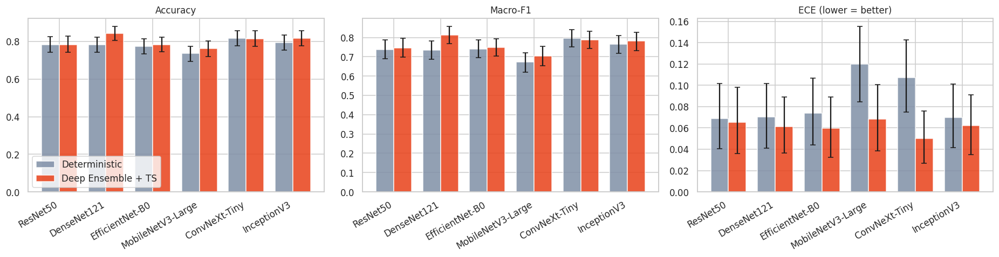

[saved figure] figures/F3_confusion_matrices.png


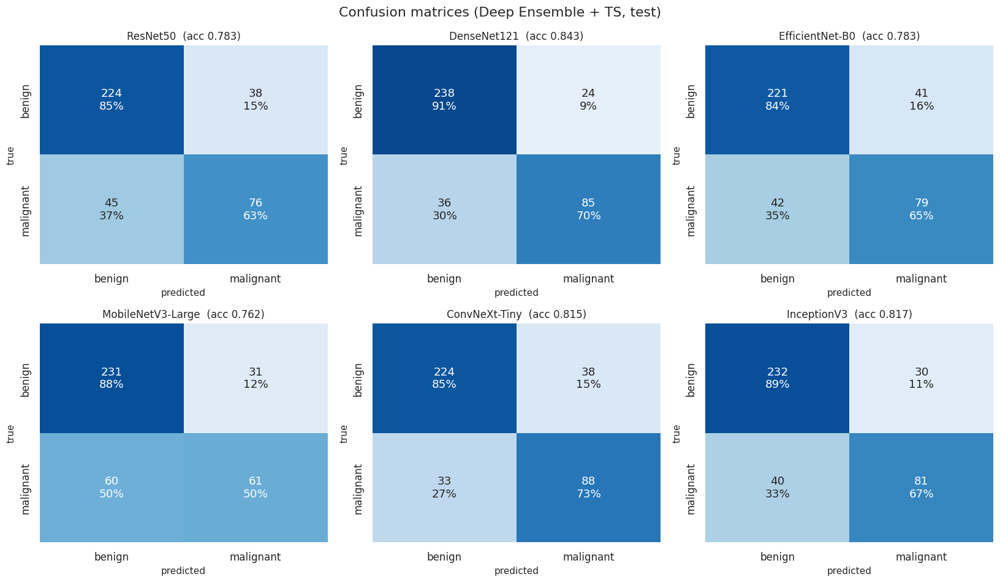

[saved figure] figures/F4_roc_curves.png


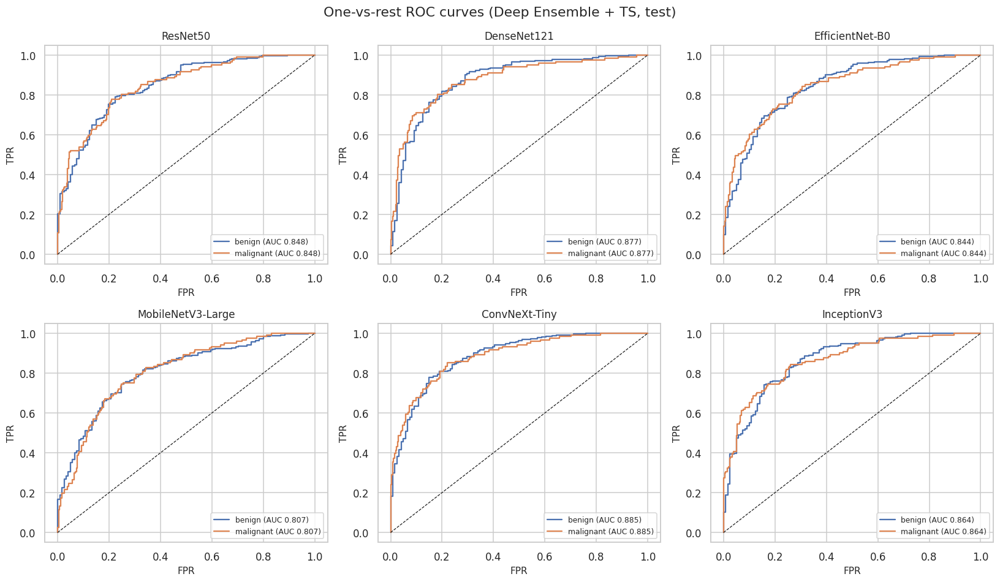

In [12]:
# ---- bootstrap confidence intervals
def boot_ci(pm, y, B=CFG.BOOT, seed=0):
    rng = np.random.default_rng(seed); n = len(y); pred = pm.argmax(1); res = {k: [] for k in ('accuracy', 'f1', 'ece', 'nll')}
    for _ in range(B):
        i = rng.integers(0, n, n)
        res['accuracy'].append((pred[i] == y[i]).mean()); res['f1'].append(f1_score(y[i], pred[i], average='macro', zero_division=0))
        res['ece'].append(ece_score(pm[i], y[i])); res['nll'].append(nll_score(pm[i], y[i]))
    return {k: (np.mean(v), np.percentile(v, 2.5), np.percentile(v, 97.5)) for k, v in res.items()}


CI = {}
rows = []
for a in ARCHS:
    for v in ('Deterministic', 'Deep Ensemble + TS'):
        CI[(a, v)] = boot_ci(PMt(a, v), yte_np)
        r = dict(architecture=a, variant=v)
        for k, (m, lo, hi) in CI[(a, v)].items():
            r[k] = f'{m:.3f} [{lo:.3f}, {hi:.3f}]'
        rows.append(r)
print('=== Table 3 | bootstrap 95% CIs (test) ===')
save_table(pd.DataFrame(rows), 'T3_bootstrap_CI', index=False)

fig, axs = plt.subplots(1, 3, figsize=(17, 4.5)); x = np.arange(len(ARCHS)); wd = .38
for ax, k in zip(axs, ('accuracy', 'f1', 'ece')):
    for o, (v, col) in enumerate((('Deterministic', '#7f8fa6'), ('Deep Ensemble + TS', '#e84118'))):
        m = np.array([CI[(a, v)][k][0] for a in ARCHS]); lo = np.array([CI[(a, v)][k][1] for a in ARCHS]); hi = np.array([CI[(a, v)][k][2] for a in ARCHS])
        ax.bar(x + (o - .5) * wd, m, wd, yerr=[m - lo, hi - m], capsize=3, label=v, color=col, alpha=.85)
    ax.set_xticks(x); ax.set_xticklabels(ARCHS, rotation=30, ha='right'); ax.set_title({'accuracy': 'Accuracy', 'f1': 'Macro-F1', 'ece': 'ECE (lower = better)'}[k])
axs[0].legend(); savefig('F2_performance_with_CI', fig)

# ---- confusion matrices + ROC curves
fig, axs = grid(len(ARCHS), 3, 5, 4.4)
for ax, a in zip(axs, ARCHS):
    pm = PMt(a, 'Deep Ensemble + TS'); cm = confusion_matrix(yte_np, pm.argmax(1), labels=list(range(NC))); cmn = cm / cm.sum(1, keepdims=True)
    ann = np.array([[f'{cm[i, j]}\n{cmn[i, j] * 100:.0f}%' for j in range(NC)] for i in range(NC)])
    sns.heatmap(cmn, annot=ann, fmt='', cmap='Blues', vmin=0, vmax=1, cbar=False, xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set_title(f'{a}  (acc {np.trace(cm) / cm.sum():.3f})'); ax.set_xlabel('predicted'); ax.set_ylabel('true')
fig.suptitle('Confusion matrices (Deep Ensemble + TS, test)'); savefig('F3_confusion_matrices', fig)

fig, axs = grid(len(ARCHS), 3, 5, 4.4)
for ax, a in zip(axs, ARCHS):
    pm = PMt(a, 'Deep Ensemble + TS')
    for c in range(NC):
        fpr, tpr, _ = roc_curve(yte_np == c, pm[:, c]); ax.plot(fpr, tpr, label=f'{CLASSES[c]} (AUC {roc_auc_score(yte_np == c, pm[:, c]):.3f})')
    ax.plot([0, 1], [0, 1], 'k--', lw=.8); ax.set_title(a); ax.set_xlabel('FPR'); ax.set_ylabel('TPR'); ax.legend(loc='lower right', fontsize=8)
fig.suptitle('One-vs-rest ROC curves (Deep Ensemble + TS, test)'); savefig('F4_roc_curves', fig)

## 4. Uncertainty quantification & probability calibration
Predictive uncertainty from probability samples `P ∈ R^{S×N×C}`:
* **Predictive entropy** `H[E_s p]` (total), **aleatoric** `E_s H[p_s]`, **mutual information** (epistemic) `MI = H[E_s p] − E_s H[p_s]`, **predictive variance** (mean over classes of the across-sample variance), and `1 − max p`.
* Calibration: **ECE**, **Brier score**, **NLL**, reliability diagrams; temperature scaling fitted on the validation split.

[saved figure] figures/F5_reliability_diagrams.png


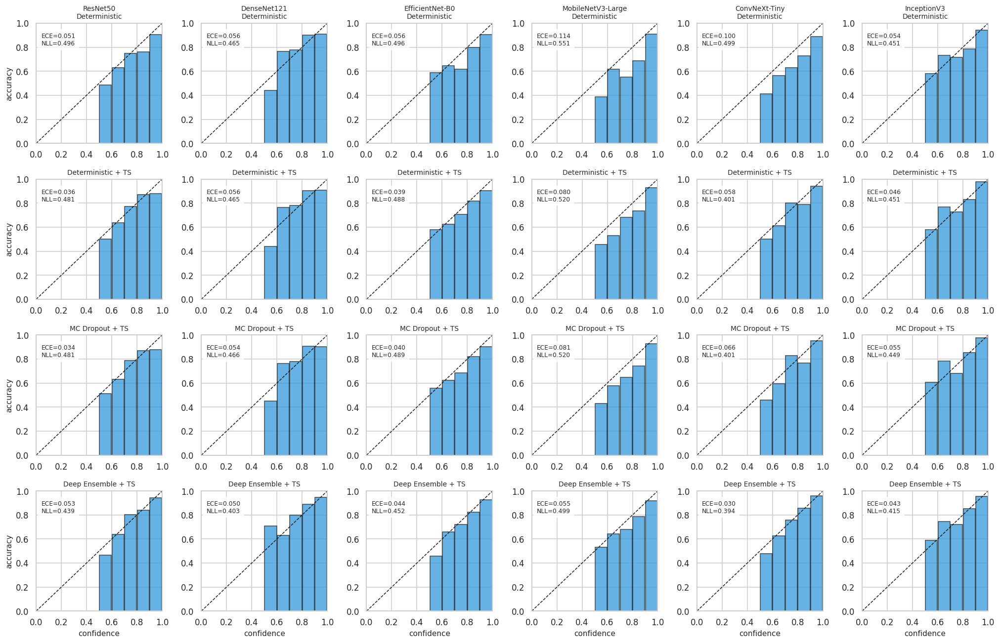

[saved figure] figures/F6_calibration_heatmaps.png


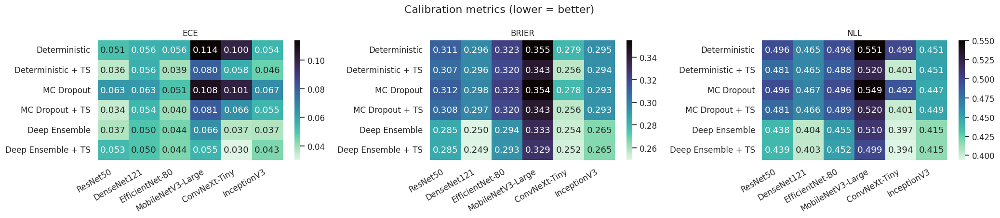

=== Table 4 | error detection AUROC by uncertainty measure (Deep Ensemble + TS) ===
[saved table] tables/T4_uncertainty_vs_errors_ensemble_TS.csv


,architecture,measure,n_errors,mean_correct,mean_wrong,auroc_error_detection,mwu_p
19,ResNet50,entropy,83,0.3891,0.5784,0.7741,0.0000
20,ResNet50,aleatoric,83,0.3444,0.5001,0.7451,0.0000
21,ResNet50,mi,83,0.0446,0.0783,0.6396,0.0000
22,ResNet50,var,83,0.0149,0.0317,0.7016,0.0000
23,ResNet50,one_minus_maxp,83,0.1709,0.3171,0.7741,0.0000
43,DenseNet121,entropy,60,0.4083,0.5422,0.7158,0.0000
44,DenseNet121,aleatoric,60,0.3625,0.4852,0.7195,0.0000
45,DenseNet121,mi,60,0.0458,0.0571,0.5613,0.0658
46,DenseNet121,var,60,0.0141,0.0221,0.6346,0.0005
47,DenseNet121,one_minus_maxp,60,0.1754,0.2759,0.7158,0.0000


[saved figure] figures/F7_uncertainty_correct_vs_wrong.png


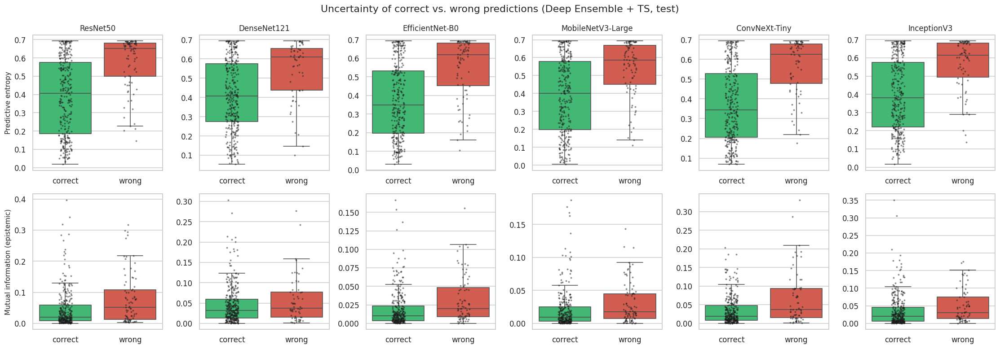

In [13]:
def uncertainty(Ps):
    pm = Ps.mean(0)
    H = -(pm * np.log(pm + EPS)).sum(-1)
    EH = -(Ps * np.log(Ps + EPS)).sum(-1).mean(0)
    mi = np.maximum(H - EH, 0) if Ps.shape[0] > 1 else np.zeros_like(H)
    var = Ps.var(0).mean(-1) if Ps.shape[0] > 1 else np.zeros_like(H)
    return dict(entropy=H, aleatoric=EH, mi=mi, var=var, one_minus_maxp=1 - pm.max(-1))


UNC = {a: {v: uncertainty(PR[a]['test'][v]) for v in VARIANTS} for a in ARCHS}
ERR = {a: {v: (PMt(a, v).argmax(1) != yte_np).astype(float) for v in VARIANTS} for a in ARCHS}

# ---- reliability diagrams (rows: variants, cols: architectures)
def reliability(ax, pm, y, nb=10, title=''):
    conf, corr = pm.max(1), pm.argmax(1) == y; edges = np.linspace(0, 1, nb + 1); cen, acc, cnt = [], [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            cen.append((lo + hi) / 2); acc.append(corr[m].mean()); cnt.append(m.sum())
    ax.bar(cen, acc, width=1 / nb * .95, alpha=.75, edgecolor='k', color='#3498db')
    ax.plot([0, 1], [0, 1], 'k--', lw=1)
    ax.text(.04, .92, f'ECE={ece_score(pm, y):.3f}\nNLL={nll_score(pm, y):.3f}', transform=ax.transAxes, va='top', fontsize=8, bbox=dict(fc='w', alpha=.8))
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_title(title, fontsize=9)


show_v = ['Deterministic', 'Deterministic + TS', 'MC Dropout + TS', 'Deep Ensemble + TS']
fig, axs = plt.subplots(len(show_v), len(ARCHS), figsize=(3.1 * len(ARCHS), 3.0 * len(show_v)), squeeze=False)
for i, v in enumerate(show_v):
    for j, a in enumerate(ARCHS):
        reliability(axs[i, j], PMt(a, v), yte_np, title=f'{a}\n{v}' if i == 0 else v)
        if j == 0:
            axs[i, j].set_ylabel('accuracy')
        if i == len(show_v) - 1:
            axs[i, j].set_xlabel('confidence')
savefig('F5_reliability_diagrams', fig)

# ---- calibration heatmaps
fig, axs = plt.subplots(1, 3, figsize=(19, 4.2))
for ax, m, cmap in zip(axs, ('ece', 'brier', 'nll'), ('mako_r', 'mako_r', 'mako_r')):
    sns.heatmap(T1.pivot(index='variant', columns='architecture', values=m).loc[VARIANTS, ARCHS], annot=True, fmt='.3f', cmap=cmap, ax=ax)
    ax.set_title(m.upper() if m != 'nll' else 'NLL'); ax.set_xlabel(''); ax.set_ylabel('')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')
fig.suptitle('Calibration metrics (lower = better)'); savefig('F6_calibration_heatmaps', fig)

# ---- uncertainty summary table: correct vs wrong, error-detection AUROC
rows = []
for a in ARCHS:
    for v in VARIANTS:
        err = ERR[a][v]
        for meas, u in UNC[a][v].items():
            if PR[a]['test'][v].shape[0] == 1 and meas in ('aleatoric', 'mi', 'var'):
                continue
            ok, bad = u[err == 0], u[err == 1]
            au = roc_auc_score(err, u) if 0 < err.sum() < len(err) else np.nan
            p = stats.mannwhitneyu(bad, ok, alternative='greater').pvalue if len(bad) > 0 and len(ok) > 0 else np.nan
            rows.append(dict(architecture=a, variant=v, measure=meas, n_errors=int(err.sum()), mean_correct=ok.mean(),
                             mean_wrong=bad.mean() if len(bad) else np.nan, auroc_error_detection=au, mwu_p=p))
T4 = pd.DataFrame(rows)
save_table(T4, 'T4_uncertainty_vs_errors', index=False, show=False, png=False)
print('=== Table 4 | error detection AUROC by uncertainty measure (Deep Ensemble + TS) ===')
save_table(T4[T4.variant == 'Deep Ensemble + TS'].drop(columns='variant'), 'T4_uncertainty_vs_errors_ensemble_TS', index=False)

# ---- correct vs wrong distributions
meas_show = [('entropy', 'Predictive entropy'), ('mi', 'Mutual information (epistemic)')]
fig, axs = plt.subplots(len(meas_show), len(ARCHS), figsize=(3.4 * len(ARCHS), 3.6 * len(meas_show)), squeeze=False)
for i, (m, mt) in enumerate(meas_show):
    for j, a in enumerate(ARCHS):
        d = pd.DataFrame(dict(u=UNC[a]['Deep Ensemble + TS'][m], status=np.where(ERR[a]['Deep Ensemble + TS'] == 1, 'wrong', 'correct')))
        sns.boxplot(data=d, x='status', y='u', order=['correct', 'wrong'], palette=['#2ecc71', '#e74c3c'], ax=axs[i, j], showfliers=False)
        sns.stripplot(data=d, x='status', y='u', order=['correct', 'wrong'], color='k', size=2.5, alpha=.5, ax=axs[i, j])
        axs[i, j].set_title(f'{a}' if i == 0 else ''); axs[i, j].set_xlabel(''); axs[i, j].set_ylabel(mt if j == 0 else '')
fig.suptitle('Uncertainty of correct vs. wrong predictions (Deep Ensemble + TS, test)'); savefig('F7_uncertainty_correct_vs_wrong', fig)

# ---- aleatoric vs epistemic scatter
fig, axs = grid(len(ARCHS), 3, 5, 4.2)
for ax, a in zip(axs, ARCHS):
    u = UNC[a]['Deep Ensemble + TS']; err = ERR[a]['Deep Ensemble + TS']
    ax.scatter(u['aleatoric'][err == 0], u['mi'][err == 0], s=18, c='#2ecc71', alpha=.7, label='correct')
    ax.scatter(u['aleatoric'][err == 1], u['mi'][err == 1], s=40, c='#e74c3c', marker='x', label='wrong')
    ax.set_xlabel('aleatoric (expected entropy)'); ax.set_ylabel('epistemic (mutual information)'); ax.set_title(a); ax.legend(fontsize=8)
fig.suptitle('Uncertainty decomposition (Deep Ensemble + TS)'); savefig('F8_aleatoric_vs_epistemic', fig)

# ---- uncertainty distribution by true class
d = pd.concat([pd.DataFrame(dict(architecture=a, true=[CLASSES[i] for i in yte_np], entropy=UNC[a]['Deep Ensemble + TS']['entropy'])) for a in ARCHS])
fig, ax = plt.subplots(figsize=(11, 4.2)); sns.boxplot(data=d, x='architecture', y='entropy', hue='true', hue_order=CLASSES, ax=ax, showfliers=False)
ax.set_title('Predictive entropy by true class (Deep Ensemble + TS)'); ax.tick_params(axis='x', rotation=20); savefig('F8b_entropy_by_class', fig)

In [14]:
# ---- subgroup analysis on the test split (BUS-BRA metadata): scanner, BI-RADS, view
te_meta = df.iloc[te_idx].reset_index(drop=True)
rows = []
for a in ARCHS:
    pm_, err_, H_ = PMt(a, 'Deep Ensemble + TS'), ERR[a]['Deep Ensemble + TS'], UNC[a]['Deep Ensemble + TS']['entropy']
    for col in ('device', 'birads', 'side'):
        for g, ix in te_meta.groupby(col).groups.items():
            ix = np.asarray(ix)
            rows.append(dict(architecture=a, factor=col, group=str(g), n=len(ix), accuracy=1 - err_[ix].mean(), mean_entropy=H_[ix].mean(),
                             ece=ece_score(pm_[ix], yte_np[ix]) if len(ix) >= 30 else np.nan))
print('=== Table 0d | test performance by scanner / BI-RADS / view (Deep Ensemble + TS; ECE only if n>=30) ===')
save_table(pd.DataFrame(rows), 'T0d_subgroup_performance', index=False)


=== Table 0d | test performance by scanner / BI-RADS / view (Deep Ensemble + TS; ECE only if n>=30) ===
[saved table] tables/T0d_subgroup_performance.csv


,architecture,factor,group,n,accuracy,mean_entropy,ece
0,ResNet50,device,GE Logiq 5 @10-12MHz,179,0.8045,0.4155,0.0839
1,ResNet50,device,GE Logiq 7 @10-14MHz,182,0.7692,0.4303,0.0563
2,ResNet50,device,Toshiba Aplio 300 @12-14 MHz,22,0.7273,0.5470,NaN
3,ResNet50,birads,2,126,0.9127,0.3221,0.0956
4,ResNet50,birads,3,88,0.8409,0.4277,0.0990
5,ResNet50,birads,4,139,0.6187,0.5155,0.1242
6,ResNet50,birads,5,30,0.8333,0.4946,0.1578
7,ResNet50,side,left,171,0.8012,0.4228,0.0471
8,ResNet50,side,right,171,0.7485,0.4224,0.0654
9,ResNet50,side,single,41,0.8537,0.4926,0.1688


## 5. Selective prediction & risk-coverage analysis
Can uncertain predictions be identified and referred for additional assessment? Samples are ranked by an uncertainty score; the most uncertain ones are rejected; the **risk** (error rate) of the retained set is plotted against **coverage**. AURC = area under the risk-coverage curve (lower = better); e-AURC subtracts the oracle (perfect-ranking) AURC.

=== Table 5 | selective prediction (entropy, Deep Ensemble + TS) ===
[saved table] tables/T5_selective_prediction_ensemble_TS.csv


,architecture,aurc,oracle_aurc,e_aurc,acc@100%cov,acc@90%cov,acc@80%cov,acc@70%cov,acc@50%cov
19,ResNet50,0.0885,0.0257,0.0629,0.7833,0.8145,0.8627,0.8806,0.9062
43,DenseNet121,0.0806,0.0132,0.0674,0.8433,0.8580,0.8824,0.9030,0.9323
67,EfficientNet-B0,0.0959,0.0257,0.0702,0.7833,0.8174,0.8399,0.8843,0.9062
91,MobileNetV3-Large,0.1185,0.0311,0.0874,0.7624,0.7884,0.8072,0.8358,0.8802
115,ConvNeXt-Tiny,0.0670,0.0186,0.0484,0.8146,0.8493,0.8856,0.9030,0.9479
139,InceptionV3,0.0789,0.0181,0.0608,0.8172,0.8493,0.8595,0.8955,0.9323


[saved figure] figures/F9_risk_coverage_per_architecture.png


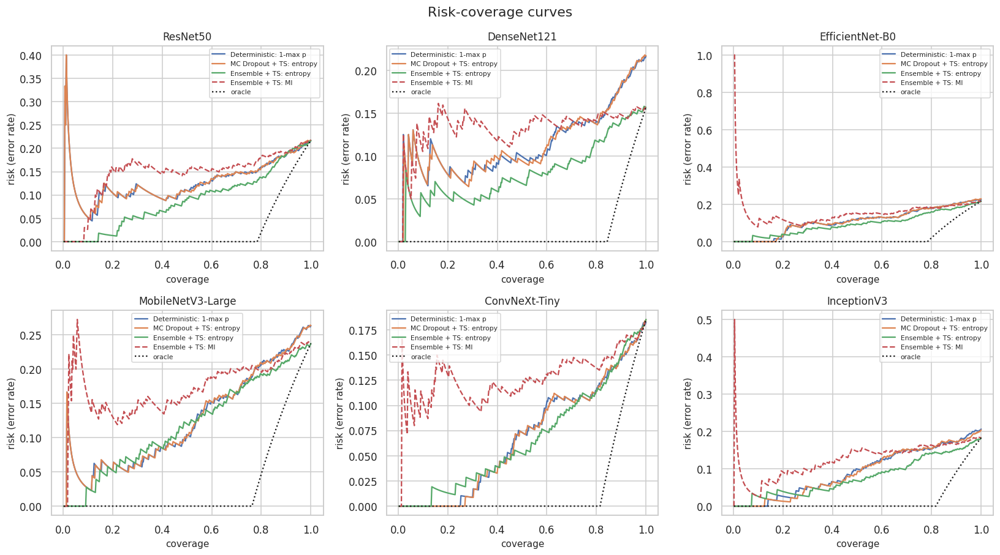

[saved figure] figures/F10_risk_coverage_comparison.png


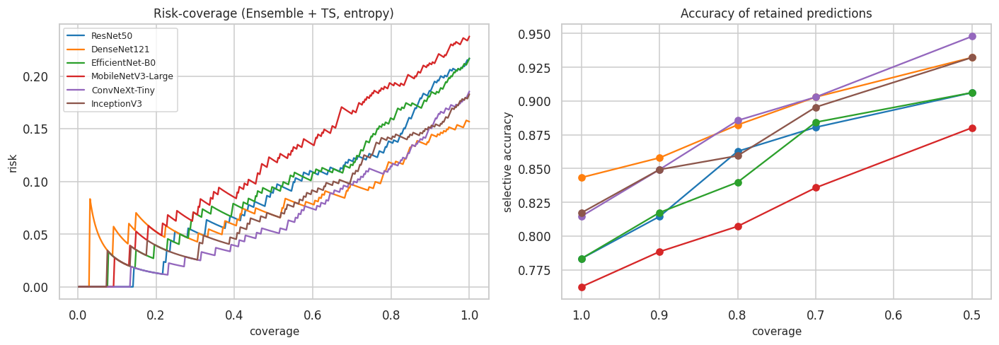

Best architecture on validation macro-F1: ConvNeXt-Tiny {'ResNet50': 0.7678, 'DenseNet121': 0.7939, 'EfficientNet-B0': 0.7951, 'MobileNetV3-Large': 0.7791, 'ConvNeXt-Tiny': 0.8165, 'InceptionV3': 0.775}


In [15]:
def risk_coverage(u, err):
    o = np.argsort(u, kind='stable'); n = len(err)
    return np.arange(1, n + 1) / n, np.cumsum(err[o]) / np.arange(1, n + 1)


def aurc(u, err):
    return float(risk_coverage(u, err)[1].mean())


def sel_acc(u, err, c):
    k = max(1, int(round(c * len(err)))); return float(1 - err[np.argsort(u, kind='stable')[:k]].mean())


COVS = [1.0, 0.9, 0.8, 0.7, 0.5]
rows = []
for a in ARCHS:
    for v in VARIANTS:
        err = ERR[a][v]; orc = aurc(err, err)
        for meas, u in UNC[a][v].items():
            if PR[a]['test'][v].shape[0] == 1 and meas in ('aleatoric', 'mi', 'var'):
                continue
            r = dict(architecture=a, variant=v, measure=meas, aurc=aurc(u, err), oracle_aurc=orc, e_aurc=aurc(u, err) - orc)
            for c in COVS:
                r[f'acc@{int(c * 100)}%cov'] = sel_acc(u, err, c)
            rows.append(r)
T5 = pd.DataFrame(rows)
save_table(T5, 'T5_selective_prediction_long', index=False, show=False, png=False)
print('=== Table 5 | selective prediction (entropy, Deep Ensemble + TS) ===')
save_table(T5[(T5.variant == 'Deep Ensemble + TS') & (T5.measure == 'entropy')].drop(columns=['variant', 'measure']), 'T5_selective_prediction_ensemble_TS', index=False)

fig, axs = grid(len(ARCHS), 3, 5, 4.2)
for ax, a in zip(axs, ARCHS):
    err = ERR[a]['Deep Ensemble + TS']
    for lab, u, err_, ls in (('Deterministic: 1-max p', UNC[a]['Deterministic']['one_minus_maxp'], ERR[a]['Deterministic'], '-'),
                             ('MC Dropout + TS: entropy', UNC[a]['MC Dropout + TS']['entropy'], ERR[a]['MC Dropout + TS'], '-'),
                             ('Ensemble + TS: entropy', UNC[a]['Deep Ensemble + TS']['entropy'], err, '-'),
                             ('Ensemble + TS: MI', UNC[a]['Deep Ensemble + TS']['mi'], err, '--')):
        c, r = risk_coverage(u, err_); ax.plot(c, r, ls, label=lab)
    c, r = risk_coverage(err, err); ax.plot(c, r, 'k:', label='oracle')
    ax.set_xlabel('coverage'); ax.set_ylabel('risk (error rate)'); ax.set_title(a); ax.legend(fontsize=7)
fig.suptitle('Risk-coverage curves'); savefig('F9_risk_coverage_per_architecture', fig)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
for a in ARCHS:
    err = ERR[a]['Deep Ensemble + TS']; c, r = risk_coverage(UNC[a]['Deep Ensemble + TS']['entropy'], err); axs[0].plot(c, r, label=a, color=PAL[a])
    c, acc_ = np.array(COVS), [sel_acc(UNC[a]['Deep Ensemble + TS']['entropy'], err, k) for k in COVS]; axs[1].plot(c, acc_, 'o-', label=a, color=PAL[a])
axs[0].set_xlabel('coverage'); axs[0].set_ylabel('risk'); axs[0].set_title('Risk-coverage (Ensemble + TS, entropy)'); axs[0].legend(fontsize=8)
axs[1].set_xlabel('coverage'); axs[1].set_ylabel('selective accuracy'); axs[1].set_title('Accuracy of retained predictions'); axs[1].invert_xaxis()
savefig('F10_risk_coverage_comparison', fig)

piv = T5[T5.variant.isin(VARIANTS) & (T5.measure.isin(['entropy', 'one_minus_maxp']))].copy()
piv = piv[((piv.variant.str.startswith('Deterministic')) & (piv.measure == 'one_minus_maxp')) | ((~piv.variant.str.startswith('Deterministic')) & (piv.measure == 'entropy'))]
fig, ax = plt.subplots(figsize=(9, 4.2)); sns.heatmap(piv.pivot(index='variant', columns='architecture', values='aurc').loc[VARIANTS, ARCHS], annot=True, fmt='.4f', cmap='rocket_r', ax=ax)
ax.set_title('AURC by variant (lower = better)'); ax.set_xlabel(''); ax.set_ylabel(''); savefig('F11_aurc_heatmap', fig)

# ---- best architecture by validation macro-F1 (never uses test labels)
valf1 = {a: cls_metrics(PMt(a, 'Deep Ensemble + TS', 'val'), yva_np)['f1'] for a in ARCHS}
valnll = {a: nll_score(PMt(a, 'Deep Ensemble + TS', 'val'), yva_np) for a in ARCHS}
BEST_ARCH = sorted(ARCHS, key=lambda a: (-round(valf1[a], 4), valnll[a]))[0]
print('Best architecture on validation macro-F1:', BEST_ARCH, {a: round(v, 4) for a, v in valf1.items()})

## 6. Robustness to image perturbations and quality variations
Perturbations are applied to the raw `[0,1]` test images (3 severities each): Gaussian noise, **speckle** noise (ultrasound-specific), Gaussian blur, reduced contrast and JPEG compression. For every architecture we track accuracy, ECE, NLL and the mean uncertainty of the deterministic model, the MC-Dropout model (+TS) and the deep ensemble (+TS) (temperatures are the ones fitted on *clean* validation data). A reliable uncertainty estimate should **rise** as quality degrades.

[saved figure] figures/F12_perturbation_examples.png


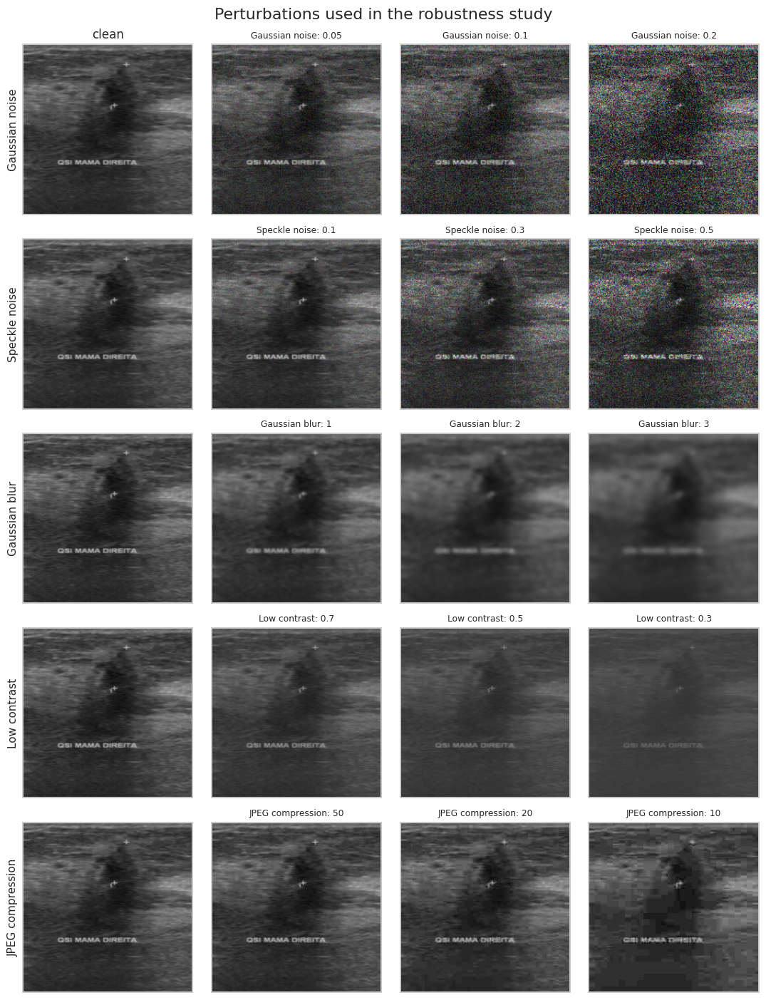

Gaussian noise lvl1:   0%|          | 0/6 [00:00<?, ?it/s]

Gaussian noise lvl2:   0%|          | 0/6 [00:00<?, ?it/s]

Gaussian noise lvl3:   0%|          | 0/6 [00:00<?, ?it/s]

Speckle noise lvl1:   0%|          | 0/6 [00:00<?, ?it/s]

Speckle noise lvl2:   0%|          | 0/6 [00:00<?, ?it/s]

Speckle noise lvl3:   0%|          | 0/6 [00:00<?, ?it/s]

... (6 outputs left out)

JPEG compression lvl1:   0%|          | 0/6 [00:00<?, ?it/s]

JPEG compression lvl2:   0%|          | 0/6 [00:00<?, ?it/s]

JPEG compression lvl3:   0%|          | 0/6 [00:00<?, ?it/s]

[saved figure] figures/F13_robustness_accuracy_ensemble.png


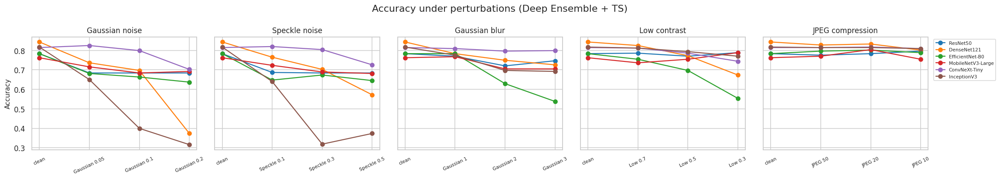

[saved figure] figures/F14_robustness_ECE_ensemble.png


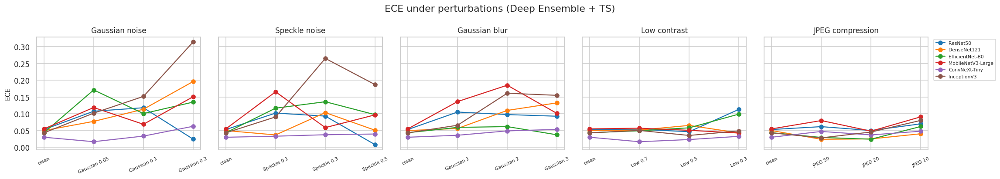

[saved figure] figures/F16_robustness_MI_ensemble.png


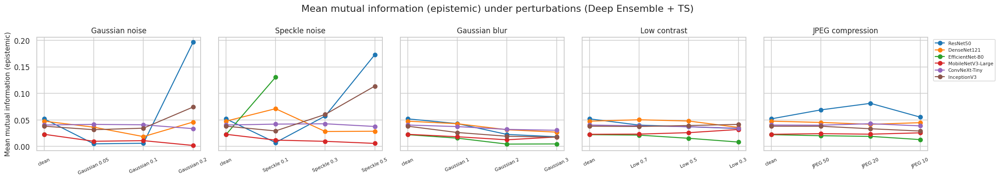

[saved figure] figures/F17_robustness_drop_heatmap.png


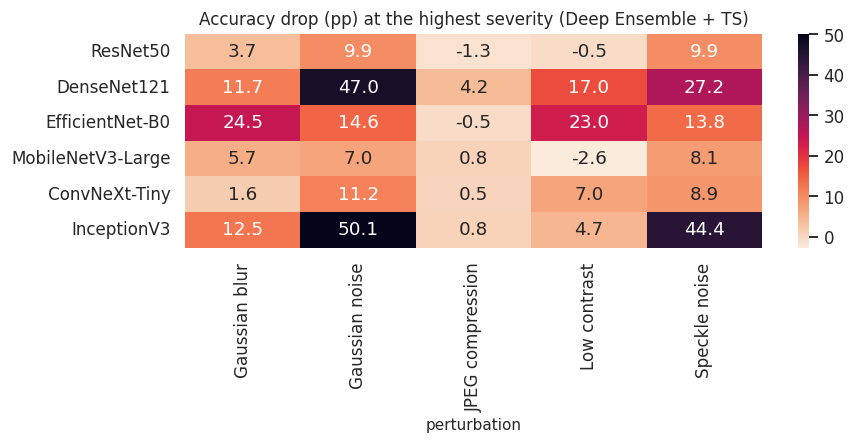

=== Table 7 | robustness summary ===
[saved table] tables/T7_robustness_summary.csv


,architecture,variant,clean_acc,perturbed_mean_acc,rel_drop_pct,clean_ece,perturbed_mean_ece,entropy_increase,mi_increase
0,ResNet50,Deterministic,0.7833,0.6762,13.6667,0.0513,0.1085,0.1631,0.0000
1,ResNet50,MC Dropout + TS,0.7859,0.6759,13.9978,0.0325,0.1069,0.1346,0.0022
2,ResNet50,Deep Ensemble + TS,0.7833,0.7363,6.0000,0.0532,0.0764,0.1169,0.0044
3,DenseNet121,Deterministic,0.7833,0.6559,16.2667,0.0560,0.1062,0.0540,0.0000
4,DenseNet121,MC Dropout + TS,0.7781,0.6581,15.4139,0.0544,0.1030,0.0583,0.0256
5,DenseNet121,Deep Ensemble + TS,0.8433,0.7225,14.3240,0.0501,0.0752,0.0978,-0.0079
6,EfficientNet-B0,Deterministic,0.7755,0.6560,15.3984,0.0565,0.1258,0.1192,0.0000
7,EfficientNet-B0,MC Dropout + TS,0.7755,0.6576,15.1964,0.0467,0.1059,0.1141,0.0059
8,EfficientNet-B0,Deep Ensemble + TS,0.7833,0.6860,12.4222,0.0437,0.0826,0.1233,0.0030
9,MobileNetV3-Large,Deterministic,0.7363,0.7128,3.1915,0.1140,0.1176,0.0599,0.0000


In [16]:
def p_gauss(x, s): return (x + torch.randn_like(x) * s).clamp(0, 1)
def p_speckle(x, s): return (x + x * torch.randn_like(x) * s).clamp(0, 1)
def p_blur(x, s):
    k = int(2 * math.ceil(3 * s) + 1); return TF.gaussian_blur(x, [k, k], [float(s), float(s)])
def p_contrast(x, f):
    m = x.mean((1, 2, 3), keepdim=True); return ((x - m) * f + m).clamp(0, 1)
def p_jpeg(x, q):
    outs = []
    for im in x:
        buf = io.BytesIO(); Image.fromarray((im.permute(1, 2, 0).numpy() * 255).astype(np.uint8)).save(buf, 'JPEG', quality=int(q)); buf.seek(0)
        outs.append(torch.from_numpy(np.asarray(Image.open(buf).convert('RGB')).copy()).permute(2, 0, 1).float() / 255.)
    return torch.stack(outs)


PERTS = {'Gaussian noise': (p_gauss, [0.05, 0.10, 0.20]), 'Speckle noise': (p_speckle, [0.10, 0.30, 0.50]),
         'Gaussian blur': (p_blur, [1, 2, 3]), 'Low contrast': (p_contrast, [0.7, 0.5, 0.3]),
         'JPEG compression': (p_jpeg, [50, 20, 10])}


def apply_pert(fn, lev, X, seed=1234):
    torch.manual_seed(seed)
    return torch.cat([fn(X[i:i + 64], lev) for i in range(0, len(X), 64)])


def eval_variants(arch, Xp):
    Ld = logits_det(MODELS[(arch, 0)], Xp)[None].numpy()
    Lm = logits_mc(MODELS[(arch, 0)], Xp, CFG.ROB_T).numpy()
    Le = np.stack([logits_det(MODELS[(arch, s)], Xp).numpy() for s in range(CFG.ENS_M)])
    out = {}
    for name, L, t in (('Deterministic', Ld, 1.0), ('MC Dropout + TS', Lm, TEMP[(arch, 'MC Dropout')]), ('Deep Ensemble + TS', Le, TEMP[(arch, 'Deep Ensemble')])):
        Ps = softmax(L / t, -1); pm = Ps.mean(0); u = uncertainty(Ps)
        out[name] = dict(acc=(pm.argmax(1) == yte_np).mean(), ece=ece_score(pm, yte_np), nll=nll_score(pm, yte_np),
                         entropy=u['entropy'].mean(), mi=u['mi'].mean(), conf=pm.max(1).mean())
    return out


# example figure of perturbations
ex_i = int(np.where(yte_np == NC - 1)[0][0])
fig, axs = plt.subplots(len(PERTS), 4, figsize=(10, 2.6 * len(PERTS)))
for r, (pn, (fn, levs)) in enumerate(PERTS.items()):
    axs[r, 0].imshow(Xte[ex_i].permute(1, 2, 0).numpy()); axs[r, 0].set_title('clean' if r == 0 else ''); axs[r, 0].set_ylabel(pn)
    for k, lev in enumerate(levs):
        axs[r, k + 1].imshow(apply_pert(fn, lev, Xte_f[ex_i:ex_i + 1])[0].permute(1, 2, 0).numpy()); axs[r, k + 1].set_title(f'{pn}: {lev}', fontsize=8)
    for a_ in axs[r]:
        a_.set_xticks([]); a_.set_yticks([])
fig.suptitle('Perturbations used in the robustness study'); savefig('F12_perturbation_examples', fig)

clean = {a: eval_variants(a, Xte_f) for a in ARCHS}
ROB = []
for pn, (fn, levs) in PERTS.items():
    for a in ARCHS:
        for v, m in clean[a].items():
            ROB.append(dict(perturbation=pn, level=0, value=0, architecture=a, variant=v, **m))
    for li, lev in enumerate(levs, 1):
        Xp = apply_pert(fn, lev, Xte_f)
        for a in tqdm(ARCHS, desc=f'{pn} lvl{li}', leave=False):
            for v, m in eval_variants(a, Xp).items():
                ROB.append(dict(perturbation=pn, level=li, value=lev, architecture=a, variant=v, **m))
ROB = pd.DataFrame(ROB)
save_table(ROB, 'T6_robustness_long', index=False, show=False, png=False)


def plot_rob(metric, variant, ylabel, name):
    fig, axs = plt.subplots(1, len(PERTS), figsize=(4.2 * len(PERTS), 3.8), sharey=True)
    for ax, pn in zip(axs, PERTS):
        d = ROB[(ROB.perturbation == pn) & (ROB.variant == variant)]
        for a in ARCHS:
            q = d[d.architecture == a].sort_values('level'); ax.plot(q.level, q[metric], 'o-', color=PAL[a], label=a)
        ax.set_xticks(range(4)); ax.set_xticklabels(['clean'] + [f'{pn.split()[0]} {v}' for v in PERTS[pn][1]], rotation=25, fontsize=7); ax.set_title(pn)
    axs[0].set_ylabel(ylabel); axs[-1].legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc='upper left'); fig.suptitle(f'{ylabel} under perturbations ({variant})')
    savefig(name, fig)


plot_rob('acc', 'Deep Ensemble + TS', 'Accuracy', 'F13_robustness_accuracy_ensemble')
plot_rob('acc', 'Deterministic', 'Accuracy', 'F13b_robustness_accuracy_deterministic')
plot_rob('ece', 'Deep Ensemble + TS', 'ECE', 'F14_robustness_ECE_ensemble')
plot_rob('entropy', 'Deep Ensemble + TS', 'Mean predictive entropy', 'F15_robustness_entropy_ensemble')
plot_rob('mi', 'Deep Ensemble + TS', 'Mean mutual information (epistemic)', 'F16_robustness_MI_ensemble')

hi = ROB[(ROB.level == 3) & (ROB.variant == 'Deep Ensemble + TS')].pivot(index='architecture', columns='perturbation', values='acc')
cl = ROB[(ROB.level == 0) & (ROB.variant == 'Deep Ensemble + TS')].groupby('architecture').acc.mean()
drop = (hi.rsub(cl, axis=0) * 100).loc[ARCHS]
fig, ax = plt.subplots(figsize=(8.5, 4.2)); sns.heatmap(drop, annot=True, fmt='.1f', cmap='rocket_r', ax=ax)
ax.set_title('Accuracy drop (pp) at the highest severity (Deep Ensemble + TS)'); ax.set_ylabel(''); savefig('F17_robustness_drop_heatmap', fig)

rows = []
for a in ARCHS:
    for v in ('Deterministic', 'MC Dropout + TS', 'Deep Ensemble + TS'):
        q = ROB[(ROB.architecture == a) & (ROB.variant == v)]; c0 = q[q.level == 0].iloc[0]; pt = q[q.level > 0]
        rows.append(dict(architecture=a, variant=v, clean_acc=c0.acc, perturbed_mean_acc=pt.acc.mean(), rel_drop_pct=100 * (c0.acc - pt.acc.mean()) / c0.acc,
                         clean_ece=c0.ece, perturbed_mean_ece=pt.ece.mean(), entropy_increase=pt.entropy.mean() - c0.entropy, mi_increase=pt.mi.mean() - c0.mi))
T7 = pd.DataFrame(rows); print('=== Table 7 | robustness summary ===')
save_table(T7, 'T7_robustness_summary', index=False)

## 7. Explainability: Grad-CAM, stability and lesion correspondence
For each test image the **target class is fixed** (MC-Dropout+TS prediction), so differences between explanations reflect model stochasticity, not a change in the explained class. We measure:

* **MC stability** `stab_mc`: mean pairwise Pearson correlation of Grad-CAMs over `CAM_T` dropout-active passes (and `iou_stab_mc`: pairwise IoU of the thresholded (≥0.5) maps).
* **Ensemble stability** `stab_ens`: the same, across the `M` independently trained ensemble members (more stochasticity than dropout alone, which acts only in the classifier head).
* **Lesion correspondence** (benign/malignant images with GT masks): energy inside the mask, *energy ratio* (energy ÷ mask area fraction; 1 = chance), IoU at threshold 0.5, and pointing-game hit (peak inside the mask) of the ensemble-mean Grad-CAM.

ResNet50: Grad-CAM done
DenseNet121: Grad-CAM done
EfficientNet-B0: Grad-CAM done
MobileNetV3-Large: Grad-CAM done
ConvNeXt-Tiny: Grad-CAM done
InceptionV3: Grad-CAM done
=== Table 9 | explanation stability and lesion correspondence (mean [95% CI]) ===
[saved table] tables/T9_explanation_summary.csv


,architecture,stab_mc,stab_ens,iou_stab_mc,iou_stab_ens,loc_energy_ratio,loc_iou,loc_point
0,ResNet50,"0.981 [0.977, 0.985]","0.642 [0.616, 0.668]","0.850 [0.839, 0.861]","0.322 [0.305, 0.338]","3.100 [2.943, 3.259]","0.198 [0.182, 0.214]","0.436 [0.386, 0.483]"
1,DenseNet121,"0.873 [0.860, 0.885]","0.641 [0.611, 0.669]","0.652 [0.635, 0.667]","0.458 [0.436, 0.481]","2.269 [2.163, 2.377]","0.233 [0.215, 0.252]","0.509 [0.457, 0.556]"
2,EfficientNet-B0,"0.956 [0.950, 0.962]","0.741 [0.720, 0.763]","0.755 [0.742, 0.768]","0.455 [0.436, 0.475]","3.473 [3.327, 3.639]","0.312 [0.294, 0.330]","0.658 [0.611, 0.702]"
3,MobileNetV3-Large,"0.978 [0.975, 0.980]","0.787 [0.770, 0.804]","0.809 [0.798, 0.819]","0.453 [0.434, 0.472]","3.408 [3.238, 3.576]","0.284 [0.266, 0.302]","0.648 [0.601, 0.695]"
4,ConvNeXt-Tiny,"0.927 [0.920, 0.934]","0.640 [0.613, 0.664]","0.680 [0.664, 0.696]","0.354 [0.333, 0.375]","4.060 [3.832, 4.299]","0.257 [0.243, 0.272]","0.509 [0.457, 0.559]"
5,InceptionV3,"0.835 [0.818, 0.852]","0.641 [0.611, 0.673]","0.623 [0.606, 0.641]","0.456 [0.436, 0.475]","1.766 [1.701, 1.828]","0.175 [0.161, 0.189]","0.272 [0.227, 0.316]"


[saved figure] figures/F18_explanation_summary.png


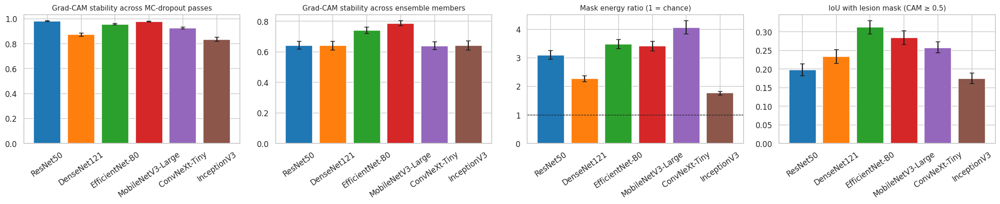

[saved figure] figures/F19_gradcam_gallery_ConvNeXt-Tiny.png


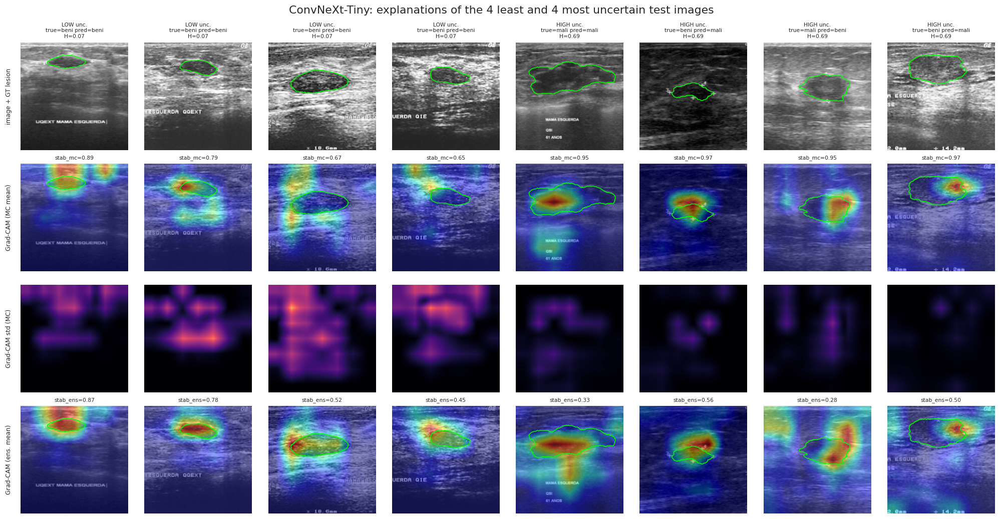

[saved figure] figures/F20_gradcam_architectures.png


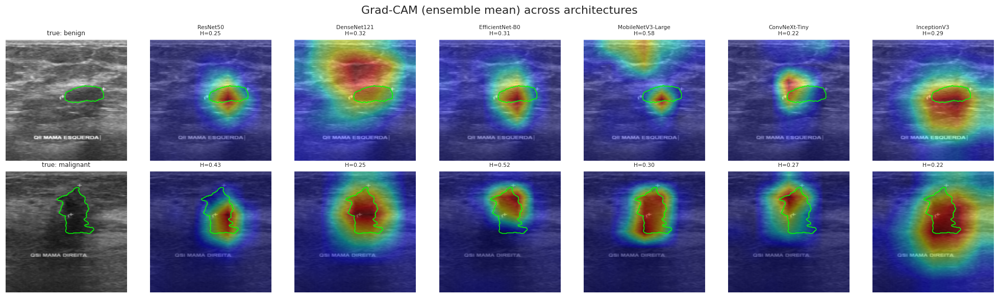

In [17]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts = model, None
        self.h = layer.register_forward_hook(lambda m, i, o: setattr(self, 'acts', o))

    def remove(self):
        self.h.remove()

    def __call__(self, x, target):
        with torch.enable_grad():
            out = self.model(x)
            g = torch.autograd.grad(out.gather(1, target[:, None]).sum(), self.acts)[0]
            a = self.acts.detach()
        w = g.mean((2, 3), keepdim=True)
        cam = F.relu((w * a).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)[:, 0]
        mn, mx = cam.amin((1, 2), keepdim=True), cam.amax((1, 2), keepdim=True)
        return ((cam - mn) / (mx - mn + 1e-8)).detach().cpu()


def run_cam(model, arch, X, target, stochastic=False, bs=16):
    gc = GradCAM(model, cam_layer(model, arch)); (enable_dropout if stochastic else (lambda m: m.eval()))(model); out = []
    for i in range(0, len(X), bs):
        out.append(gc(X[i:i + bs].to(device), target[i:i + bs].to(device)))
    gc.remove(); model.eval()
    return torch.cat(out).numpy()


def norm01(c):
    c = np.asarray(c, np.float64); mn, mx = c.min(), c.max(); return (c - mn) / (mx - mn + 1e-8)


def pair_pearson(c):
    n = c.shape[0]
    if n < 2:
        return np.nan
    f = c.reshape(n, -1).astype(np.float64); f = f - f.mean(1, keepdims=True); f /= (np.linalg.norm(f, axis=1, keepdims=True) + 1e-8)
    return float((f @ f.T)[np.triu_indices(n, 1)].mean())


def pair_iou(c, thr=0.5):
    n = c.shape[0]
    if n < 2:
        return np.nan
    b = (c.reshape(n, -1) >= thr).astype(np.float64); inter = b @ b.T; s = b.sum(1)
    return float((inter / (s[:, None] + s[None] - inter + 1e-8))[np.triu_indices(n, 1)].mean())


def loc_metrics(cam, m):
    cam = norm01(cam); frac = m.mean(); en = (cam * m).sum() / (cam.sum() + 1e-8); b = cam >= 0.5
    return dict(loc_energy=en, loc_energy_ratio=en / (frac + 1e-8), loc_iou=(b & m).sum() / ((b | m).sum() + 1e-8),
                loc_point=float(m[np.unravel_index(cam.argmax(), cam.shape)]), mask_frac=frac)


CAM, rows = {}, []
for arch in ARCHS:
    m0 = MODELS[(arch, 0)]
    tgt = torch.from_numpy(PMt(arch, 'MC Dropout + TS').argmax(1))
    cam_det = run_cam(m0, arch, Xte_f, tgt, False)
    cams_mc = np.stack([run_cam(m0, arch, Xte_f, tgt, True) for _ in range(CFG.CAM_T)]).astype(np.float32)
    cams_en = np.stack([run_cam(MODELS[(arch, s)], arch, Xte_f, tgt, False) for s in range(CFG.ENS_M)]).astype(np.float32)
    ens_mean = np.stack([norm01(c) for c in cams_en.mean(0)])
    CAM[arch] = dict(det=cam_det.astype(np.float16), mc_mean=cams_mc.mean(0).astype(np.float16), mc_std=cams_mc.std(0).astype(np.float16),
                     ens_mean=ens_mean.astype(np.float16), ens_std=cams_en.std(0).astype(np.float16))
    um, ue, ud = UNC[arch]['MC Dropout + TS'], UNC[arch]['Deep Ensemble + TS'], UNC[arch]['Deterministic + TS']
    pe = PMt(arch, 'Deep Ensemble + TS').argmax(1)
    for i in range(len(yte_np)):
        mk = Mte[i].numpy()
        r = dict(arch=arch, idx=i, y=int(yte_np[i]), cls=CLASSES[yte_np[i]], pred=int(pe[i]), correct=int(pe[i] == yte_np[i]),
                 entropy_det=ud['entropy'][i], entropy_mc=um['entropy'][i], mi_mc=um['mi'][i], var_mc=um['var'][i],
                 entropy_ens=ue['entropy'][i], mi_ens=ue['mi'][i], var_ens=ue['var'][i],
                 stab_mc=pair_pearson(cams_mc[:, i]), stab_ens=pair_pearson(cams_en[:, i]),
                 iou_stab_mc=pair_iou(cams_mc[:, i]), iou_stab_ens=pair_iou(cams_en[:, i]), has_lesion=int(mk.any()))
        r.update(loc_metrics(ens_mean[i], mk) if mk.any() else dict(loc_energy=np.nan, loc_energy_ratio=np.nan, loc_iou=np.nan, loc_point=np.nan, mask_frac=0.0))
        rows.append(r)
    del cams_mc, cams_en
    print(f'{arch}: Grad-CAM done')
EXP = pd.DataFrame(rows)
save_table(EXP, 'T8_per_image_explanation_metrics', index=False, show=False, png=False)

# ---- summary per architecture (with bootstrap CIs for means)
def boot_mean(x, B=CFG.BOOT, seed=0):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    if len(x) == 0:
        return np.nan, np.nan, np.nan
    b = np.random.default_rng(seed).choice(x, (B, len(x))).mean(1); return x.mean(), np.percentile(b, 2.5), np.percentile(b, 97.5)


rows = []
for a in ARCHS:
    d = EXP[EXP.arch == a]; r = dict(architecture=a)
    for k in ('stab_mc', 'stab_ens', 'iou_stab_mc', 'iou_stab_ens', 'loc_energy_ratio', 'loc_iou', 'loc_point'):
        m, lo, hi = boot_mean(d[k]); r[k] = f'{m:.3f} [{lo:.3f}, {hi:.3f}]'
    rows.append(dict(r))
print('=== Table 9 | explanation stability and lesion correspondence (mean [95% CI]) ===')
save_table(pd.DataFrame(rows), 'T9_explanation_summary', index=False)

fig, axs = plt.subplots(1, 4, figsize=(20, 4.2))
for ax, (k, t) in zip(axs, (('stab_mc', 'Grad-CAM stability across MC-dropout passes'), ('stab_ens', 'Grad-CAM stability across ensemble members'),
                            ('loc_energy_ratio', 'Mask energy ratio (1 = chance)'), ('loc_iou', 'IoU with lesion mask (CAM ≥ 0.5)'))):
    ms = [boot_mean(EXP[EXP.arch == a][k]) for a in ARCHS]; m = np.array([x[0] for x in ms]); lo = np.array([x[1] for x in ms]); h_ = np.array([x[2] for x in ms])
    ax.bar(ARCHS, m, yerr=[m - lo, h_ - m], capsize=3, color=[PAL[a] for a in ARCHS]); ax.set_title(t, fontsize=10); ax.tick_params(axis='x', rotation=35)
    if k == 'loc_energy_ratio':
        ax.axhline(1, color='k', ls='--', lw=.8)
savefig('F18_explanation_summary', fig)

# ---- Qualitative galleries
def overlay(ax, img, cam=None, mask=None, alpha=.45):
    ax.imshow(img)
    if cam is not None:
        ax.imshow(np.asarray(cam, np.float32), cmap='jet', alpha=alpha, vmin=0, vmax=1)
    if mask is not None and mask.any():
        ax.contour(mask, [0.5], colors='lime', linewidths=1)
    ax.axis('off')


def gallery(arch, name):
    d = EXP[EXP.arch == arch].sort_values('entropy_ens'); sel = list(d.idx.values[:4]) + list(d.idx.values[-4:])
    vmax = max(float(CAM[arch]['mc_std'][sel].max()), float(CAM[arch]['ens_std'][sel].max()), 1e-3)
    fig, axs = plt.subplots(4, 8, figsize=(2.3 * 8, 2.4 * 4))
    for j, i in enumerate(sel):
        row = d[d.idx == i].iloc[0]; img = Xte[i].permute(1, 2, 0).numpy(); mk = Mte[i].numpy()
        overlay(axs[0, j], img, None, mk); axs[0, j].set_title(f"{'LOW' if j < 4 else 'HIGH'} unc.\ntrue={CLASSES[int(row.y)][:4]} pred={CLASSES[int(row.pred)][:4]}\nH={row.entropy_ens:.2f}", fontsize=7)
        overlay(axs[1, j], img, CAM[arch]['mc_mean'][i], mk); axs[1, j].set_title(f'stab_mc={row.stab_mc:.2f}', fontsize=7)
        axs[2, j].imshow(np.asarray(CAM[arch]['mc_std'][i], np.float32), cmap='magma', vmin=0, vmax=vmax); axs[2, j].axis('off')
        overlay(axs[3, j], img, CAM[arch]['ens_mean'][i], mk); axs[3, j].set_title(f'stab_ens={row.stab_ens:.2f}', fontsize=7)
    for r, t in enumerate(('image + GT lesion', 'Grad-CAM (MC mean)', 'Grad-CAM std (MC)', 'Grad-CAM (ens. mean)')):
        axs[r, 0].text(-0.08, .5, t, transform=axs[r, 0].transAxes, rotation=90, va='center', ha='right', fontsize=8)
    fig.suptitle(f'{arch}: explanations of the 4 least and 4 most uncertain test images'); savefig(name, fig)


gallery(BEST_ARCH, f'F19_gradcam_gallery_{BEST_ARCH}')
if len(ARCHS) > 1:
    other = [a for a in ARCHS if a != BEST_ARCH][0]; gallery(other, f'F19b_gradcam_gallery_{other}')

pick = [int(np.where(yte_np == c)[0][0]) for c in range(NC)]
fig, axs = plt.subplots(NC, len(ARCHS) + 1, figsize=(2.6 * (len(ARCHS) + 1), 2.7 * NC))
for r, i in enumerate(pick):
    overlay(axs[r, 0], Xte[i].permute(1, 2, 0).numpy(), None, Mte[i].numpy()); axs[r, 0].set_title(f'true: {CLASSES[yte_np[i]]}', fontsize=8)
    for c, a in enumerate(ARCHS, 1):
        overlay(axs[r, c], Xte[i].permute(1, 2, 0).numpy(), CAM[a]['ens_mean'][i], Mte[i].numpy())
        axs[r, c].set_title(f"{a}\nH={UNC[a]['Deep Ensemble + TS']['entropy'][i]:.2f}" if r == 0 else f"H={UNC[a]['Deep Ensemble + TS']['entropy'][i]:.2f}", fontsize=7)
fig.suptitle('Grad-CAM (ensemble mean) across architectures'); savefig('F20_gradcam_architectures', fig)

## 8. Core analysis: predictive uncertainty vs. explanation reliability
Do highly uncertain predictions come with less consistent explanations and weaker lesion correspondence? We report Spearman correlations (bootstrap 95% CI) per architecture and pooled (within-architecture percentile ranks), tercile comparisons and correct-vs-wrong contrasts. Negative ρ between uncertainty and stability means *more uncertainty ↔ less stable explanations*.

=== Table 10 | Spearman rho: uncertainty vs explanation stability (entropy/MI from ensemble) ===
[saved table] tables/T10_spearman_stability_ensemble_unc.csv


,group,uncertainty,explanation_metric,rho [95% CI],p,n
28,ResNet50,entropy_ens,stab_mc,"-0.610 [-0.671, -0.552]",0.0000,383
29,ResNet50,entropy_ens,stab_ens,"-0.728 [-0.774, -0.685]",0.0000,383
35,ResNet50,mi_ens,stab_mc,"-0.190 [-0.295, -0.090]",0.0002,383
36,ResNet50,mi_ens,stab_ens,"-0.469 [-0.551, -0.385]",0.0000,383
77,DenseNet121,entropy_ens,stab_mc,"-0.470 [-0.546, -0.389]",0.0000,383
78,DenseNet121,entropy_ens,stab_ens,"-0.693 [-0.748, -0.638]",0.0000,383
84,DenseNet121,mi_ens,stab_mc,"-0.247 [-0.341, -0.149]",0.0000,383
85,DenseNet121,mi_ens,stab_ens,"-0.398 [-0.487, -0.311]",0.0000,383
126,EfficientNet-B0,entropy_ens,stab_mc,"-0.708 [-0.756, -0.654]",0.0000,383
127,EfficientNet-B0,entropy_ens,stab_ens,"-0.535 [-0.598, -0.473]",0.0000,383


[saved figure] figures/F21_rho_uncertainty_vs_stability.png


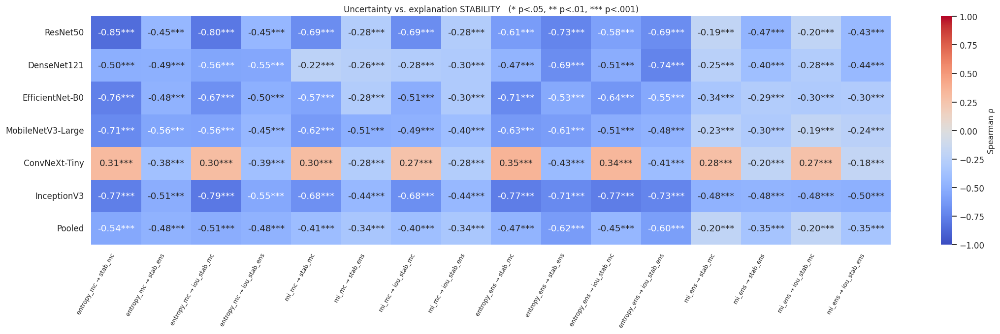

[saved figure] figures/F22_rho_uncertainty_vs_localization.png


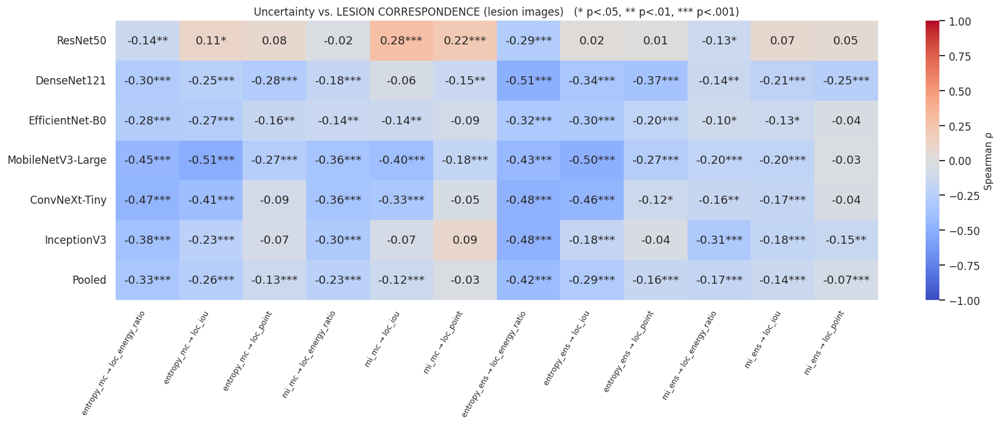

[saved figure] figures/F23_scatter_entropy_vs_ens_stability.png


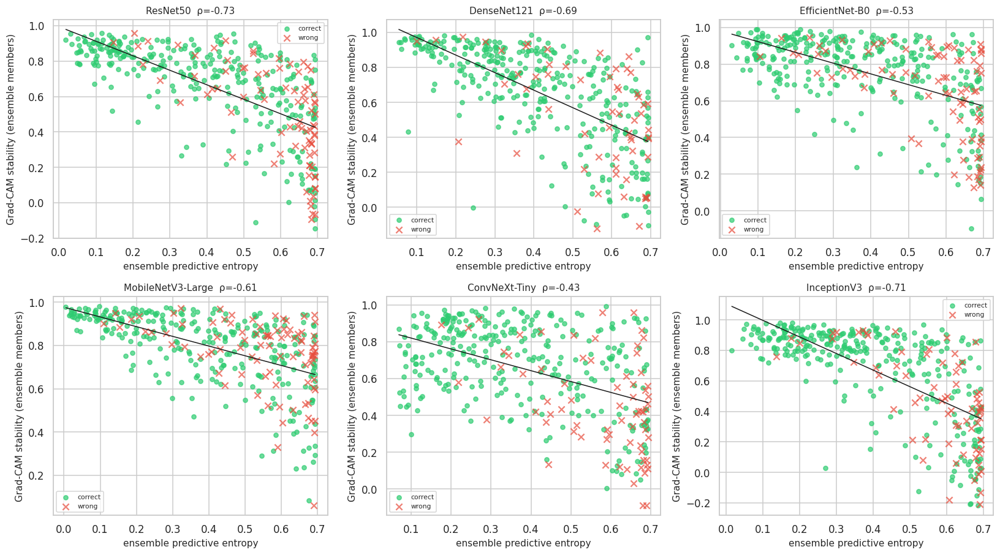

[saved figure] figures/F26_tercile_entropy_ens_stability.png


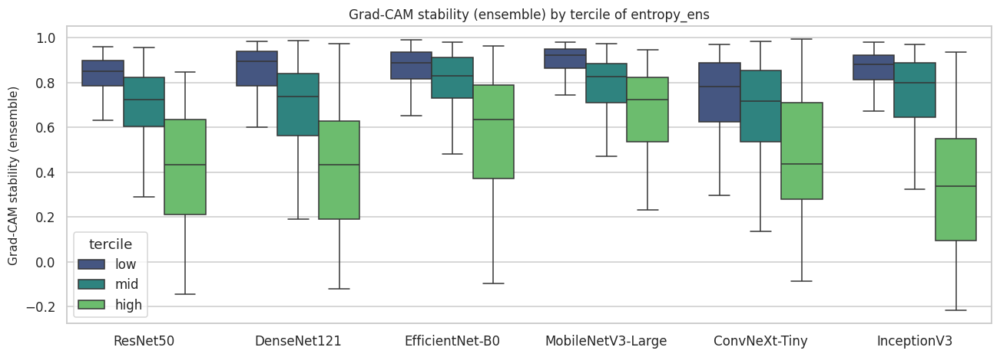

[saved table] tables/T11a_tercile_stab_ens_by_entropy_ens.csv


tercile,low,mid,high
arch,,,
ResNet50,0.8277,0.6819,0.4154
DenseNet121,0.8397,0.6642,0.4178
EfficientNet-B0,0.8564,0.7911,0.5748
MobileNetV3-Large,0.8957,0.7944,0.6721
ConvNeXt-Tiny,0.7524,0.6862,0.4812
InceptionV3,0.8566,0.7176,0.3498


=== Table 12 | explanation reliability: correct vs wrong predictions ===
[saved table] tables/T12_explanation_correct_vs_wrong.csv


,architecture,metric,n_wrong,mean_correct,mean_wrong,mwu_p
0,ResNet50,stab_mc,83,0.9840,0.9704,0.0000
1,ResNet50,stab_ens,83,0.6792,0.5054,0.0000
2,ResNet50,iou_stab_mc,83,0.8639,0.8005,0.0000
3,ResNet50,iou_stab_ens,83,0.3463,0.2337,0.0000
4,ResNet50,loc_energy_ratio,83,3.2610,2.5168,0.0000
5,ResNet50,loc_iou,83,0.2007,0.1871,0.1061
6,ResNet50,loc_point,83,0.4400,0.4217,0.3833
7,DenseNet121,stab_mc,60,0.8772,0.8509,0.0246
8,DenseNet121,stab_ens,60,0.6637,0.5161,0.0002
9,DenseNet121,iou_stab_mc,60,0.6597,0.6088,0.0092


[saved figure] figures/F29_explanation_correct_vs_wrong.png


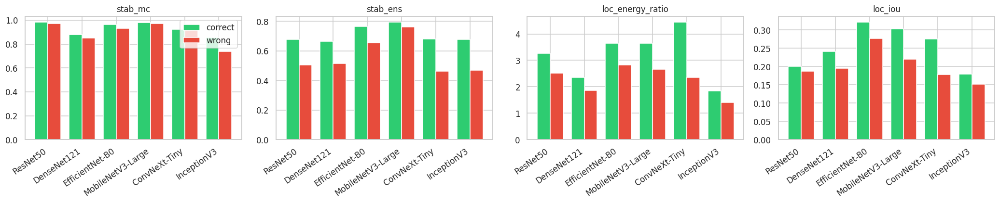

In [18]:
UNC_COLS = ['entropy_det', 'entropy_mc', 'mi_mc', 'var_mc', 'entropy_ens', 'mi_ens', 'var_ens']
STAB_COLS = ['stab_mc', 'stab_ens', 'iou_stab_mc', 'iou_stab_ens']
LOC_COLS = ['loc_energy_ratio', 'loc_iou', 'loc_point']
EXPp = EXP.copy()
for c in UNC_COLS + STAB_COLS + LOC_COLS:
    EXPp[c] = EXP.groupby('arch')[c].rank(pct=True)


def spearman_ci(x, y, B=500, seed=0):
    x = np.asarray(x, float); y = np.asarray(y, float); m = ~(np.isnan(x) | np.isnan(y)); x, y = x[m], y[m]; n = len(x)
    if n < 8 or np.ptp(x) == 0 or np.ptp(y) == 0:
        return dict(rho=np.nan, p=np.nan, lo=np.nan, hi=np.nan, n=n)
    rho, p = stats.spearmanr(x, y); rx, ry = stats.rankdata(x), stats.rankdata(y)
    I = np.random.default_rng(seed).integers(0, n, (B, n)); a = rx[I]; b = ry[I]; a = a - a.mean(1, keepdims=True); b = b - b.mean(1, keepdims=True)
    r = (a * b).sum(1) / (np.sqrt((a ** 2).sum(1) * (b ** 2).sum(1)) + 1e-12)
    return dict(rho=rho, p=p, lo=np.nanpercentile(r, 2.5), hi=np.nanpercentile(r, 97.5), n=n)


GROUPS = ARCHS + ['Pooled']
rows = []
for g in GROUPS:
    dg = EXPp if g == 'Pooled' else EXP[EXP.arch == g]
    for u in UNC_COLS:
        for m in STAB_COLS + LOC_COLS:
            rows.append(dict(group=g, uncertainty=u, explanation_metric=m, **spearman_ci(dg[u], dg[m])))
T10 = pd.DataFrame(rows)
save_table(T10, 'T10_uncertainty_vs_explanation_spearman', index=False, show=False, png=False)
print('=== Table 10 | Spearman rho: uncertainty vs explanation stability (entropy/MI from ensemble) ===')
show = T10[(T10.uncertainty.isin(['entropy_ens', 'mi_ens'])) & (T10.explanation_metric.isin(['stab_mc', 'stab_ens']))].copy()
show['rho [95% CI]'] = show.apply(lambda r: f'{r.rho:.3f} [{r.lo:.3f}, {r.hi:.3f}]', axis=1)
save_table(show[['group', 'uncertainty', 'explanation_metric', 'rho [95% CI]', 'p', 'n']], 'T10_spearman_stability_ensemble_unc', index=False)


def rho_heat(uncs, mets, title, name):
    sub = T10[T10.uncertainty.isin(uncs) & T10.explanation_metric.isin(mets)].copy(); sub['col'] = sub.uncertainty + ' → ' + sub.explanation_metric
    cols = [u + ' → ' + m for u in uncs for m in mets]
    R = sub.pivot(index='group', columns='col', values='rho').loc[GROUPS, cols]; P = sub.pivot(index='group', columns='col', values='p').loc[GROUPS, cols]
    ann = np.array([[('' if np.isnan(R.iloc[i, j]) else f'{R.iloc[i, j]:.2f}' + ('***' if P.iloc[i, j] < .001 else '**' if P.iloc[i, j] < .01 else '*' if P.iloc[i, j] < .05 else ''))
                     for j in range(R.shape[1])] for i in range(R.shape[0])])
    fig, ax = plt.subplots(figsize=(1.15 * len(cols) + 2, 0.55 * len(GROUPS) + 2.5))
    sns.heatmap(R.astype(float), annot=ann, fmt='', cmap='coolwarm', center=0, vmin=-1, vmax=1, ax=ax, cbar_kws=dict(label='Spearman ρ'))
    ax.set_title(title + '   (* p<.05, ** p<.01, *** p<.001)'); ax.set_xlabel(''); ax.set_ylabel(''); ax.set_xticklabels(ax.get_xticklabels(), rotation=60, ha='right', fontsize=8)
    savefig(name, fig)


rho_heat(['entropy_mc', 'mi_mc', 'entropy_ens', 'mi_ens'], STAB_COLS, 'Uncertainty vs. explanation STABILITY', 'F21_rho_uncertainty_vs_stability')
rho_heat(['entropy_mc', 'mi_mc', 'entropy_ens', 'mi_ens'], LOC_COLS, 'Uncertainty vs. LESION CORRESPONDENCE (lesion images)', 'F22_rho_uncertainty_vs_localization')


def scatter_grid(xc, yc, name, xl, yl):
    fig, axs = grid(len(ARCHS), 3, 5, 4.2)
    for ax, a in zip(axs, ARCHS):
        d = EXP[EXP.arch == a].dropna(subset=[xc, yc])
        for ok, col, mk in ((1, '#2ecc71', 'o'), (0, '#e74c3c', 'x')):
            q = d[d.correct == ok]; ax.scatter(q[xc], q[yc], c=col, marker=mk, s=22 if ok else 45, alpha=.7, label='correct' if ok else 'wrong')
        if len(d) > 3 and d[xc].nunique() > 2:
            k = np.polyfit(d[xc], d[yc], 1); xs = np.linspace(d[xc].min(), d[xc].max(), 20); ax.plot(xs, np.polyval(k, xs), 'k-', lw=1)
            ax.set_title(f"{a}  ρ={stats.spearmanr(d[xc], d[yc])[0]:.2f}", fontsize=10)
        ax.set_xlabel(xl); ax.set_ylabel(yl); ax.legend(fontsize=7)
    savefig(name, fig)


scatter_grid('entropy_ens', 'stab_ens', 'F23_scatter_entropy_vs_ens_stability', 'ensemble predictive entropy', 'Grad-CAM stability (ensemble members)')
scatter_grid('mi_mc', 'stab_mc', 'F24_scatter_MI_vs_mc_stability', 'MC-dropout mutual information', 'Grad-CAM stability (MC passes)')
scatter_grid('entropy_ens', 'loc_energy_ratio', 'F25_scatter_entropy_vs_localization', 'ensemble predictive entropy', 'mask energy ratio (lesion images)')

# ---- tercile analysis
def tercile_plot(unc, met, ylabel, name):
    parts = []
    for a in ARCHS:
        d = EXP[EXP.arch == a].dropna(subset=[unc, met]).copy(); d['tercile'] = pd.qcut(d[unc].rank(method='first'), 3, labels=['low', 'mid', 'high']); parts.append(d)
    d = pd.concat(parts)
    fig, ax = plt.subplots(figsize=(12, 4.4)); sns.boxplot(data=d, x='arch', y=met, hue='tercile', order=ARCHS, palette='viridis', showfliers=False, ax=ax)
    ax.set_xlabel(''); ax.set_ylabel(ylabel); ax.set_title(f'{ylabel} by tercile of {unc}'); savefig(name, fig)
    return d.groupby(['arch', 'tercile'])[met].mean().unstack()


t_a = tercile_plot('entropy_ens', 'stab_ens', 'Grad-CAM stability (ensemble)', 'F26_tercile_entropy_ens_stability')
t_b = tercile_plot('entropy_mc', 'stab_mc', 'Grad-CAM stability (MC)', 'F27_tercile_entropy_mc_stability')
t_c = tercile_plot('entropy_ens', 'loc_energy_ratio', 'Mask energy ratio', 'F28_tercile_entropy_ens_localization')
save_table(t_a.loc[ARCHS], 'T11a_tercile_stab_ens_by_entropy_ens'); save_table(t_b.loc[ARCHS], 'T11b_tercile_stab_mc_by_entropy_mc'); save_table(t_c.loc[ARCHS], 'T11c_tercile_loc_by_entropy_ens')

# ---- correct vs wrong
rows = []
for a in ARCHS:
    d = EXP[EXP.arch == a]
    for m in STAB_COLS + LOC_COLS:
        ok, bad = d[d.correct == 1][m].dropna(), d[d.correct == 0][m].dropna()
        rows.append(dict(architecture=a, metric=m, n_wrong=len(bad), mean_correct=ok.mean(), mean_wrong=bad.mean() if len(bad) else np.nan,
                         mwu_p=stats.mannwhitneyu(ok, bad, alternative='greater').pvalue if len(bad) > 1 and len(ok) > 1 else np.nan))
T12 = pd.DataFrame(rows); print('=== Table 12 | explanation reliability: correct vs wrong predictions ===')
save_table(T12, 'T12_explanation_correct_vs_wrong', index=False)
fig, axs = plt.subplots(1, 4, figsize=(19, 4)); wd = .38
for ax, m in zip(axs, ['stab_mc', 'stab_ens', 'loc_energy_ratio', 'loc_iou']):
    q = T12[T12.metric == m].set_index('architecture').loc[ARCHS]
    ax.bar(np.arange(len(ARCHS)) - wd / 2, q.mean_correct, wd, label='correct', color='#2ecc71'); ax.bar(np.arange(len(ARCHS)) + wd / 2, q.mean_wrong, wd, label='wrong', color='#e74c3c')
    ax.set_xticks(range(len(ARCHS))); ax.set_xticklabels(ARCHS, rotation=35, ha='right'); ax.set_title(m)
axs[0].legend(); savefig('F29_explanation_correct_vs_wrong', fig)

# ---- per true class
tc = EXP.groupby(['arch', 'cls'])[['stab_mc', 'stab_ens', 'entropy_ens', 'loc_energy_ratio', 'loc_iou', 'loc_point']].mean()
save_table(tc, 'T13_explanation_by_true_class')

## 9. SHAP explanations (best architecture) and their stability
Expected-gradients SHAP (`shap.GradientExplainer`) is run on test images chosen to **span the uncertainty range** of the best architecture (selected on validation macro-F1). Stability is measured (i) over repeated runs of the stochastic (dropout-active) model and (ii) across ensemble members; both are compared with Grad-CAM and with predictive uncertainty. `n` is small (`CFG.SHAP_N`), so correlations here are indicative only. This cell is wrapped in `try/except`, so a SHAP/version problem cannot stop the rest of the notebook.

=== Table 14 | SHAP (ConvNeXt-Tiny): uncertainty vs explanation metrics (n=16) ===
[saved table] tables/T14_shap_uncertainty_spearman.csv


,uncertainty,metric,rho,p,ci_lo,ci_hi,n
0,entropy_ens,shap_stab_rep,-0.1412,0.6020,-0.6735,0.3761,16
1,entropy_ens,shap_stab_ens,-0.3176,0.2306,-0.6457,0.1529,16
2,entropy_ens,shap_cam_corr,-0.6765,0.0040,-0.8646,-0.4076,16
3,entropy_ens,gradcam_stab_ens,-0.6294,0.0090,-0.8506,-0.2903,16
4,entropy_ens,shap_loc_energy_ratio,-0.3235,0.2216,-0.6854,0.0652,16
5,mi_ens,shap_stab_rep,0.0147,0.9569,-0.4482,0.4902,16
6,mi_ens,shap_stab_ens,0.0088,0.9741,-0.4190,0.4700,16
7,mi_ens,shap_cam_corr,-0.0676,0.8034,-0.4230,0.3343,16
8,mi_ens,gradcam_stab_ens,-0.2412,0.3682,-0.6503,0.2527,16
9,mi_ens,shap_loc_energy_ratio,0.0794,0.7700,-0.3830,0.5466,16


[saved figure] figures/F30_shap_gallery.png


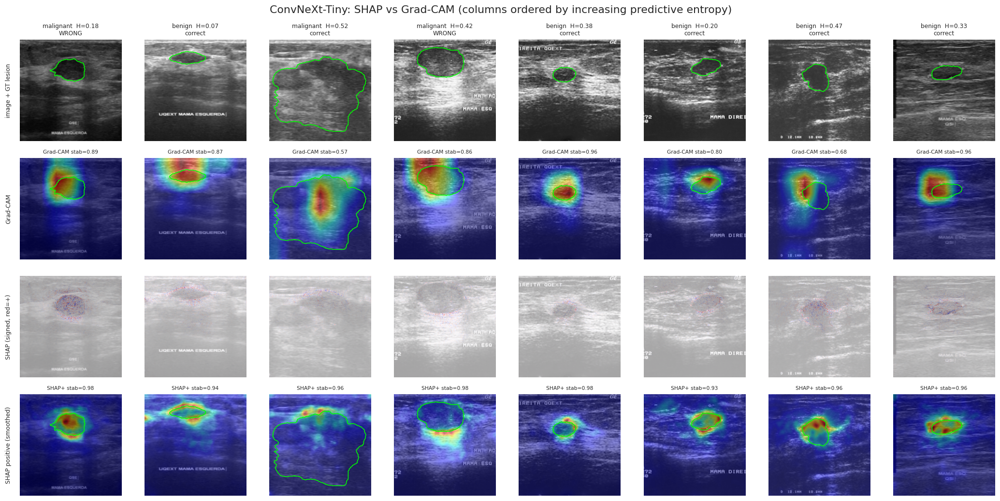

[saved figure] figures/F31_shap_uncertainty_scatter.png


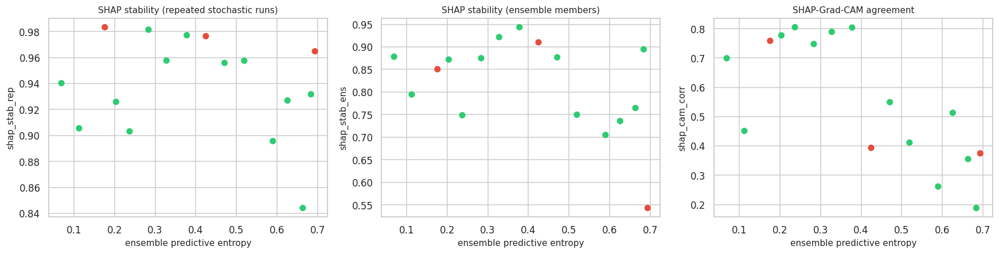

In [19]:
SHAPDF = None
try:
    import shap
    arch = BEST_ARCH
    order = np.argsort(UNC[arch]['Deep Ensemble + TS']['entropy'])
    sel = np.unique(order[np.linspace(0, len(order) - 1, CFG.SHAP_N).round().astype(int)])
    tgt_all = PMt(arch, 'MC Dropout + TS').argmax(1); tgt = tgt_all[sel]
    Xsel = Xte_f[sel].to(device)
    bg = (Xtr[np.random.default_rng(0).choice(len(Xtr), 32, replace=False)].float() / 255.).to(device)

    def sv_to_signed(sv, t):
        arr = np.stack(sv, -1) if isinstance(sv, list) else np.asarray(sv)
        if arr.shape[-1] != NC and arr.shape[0] == NC:
            arr = np.moveaxis(arr, 0, -1)
        return np.stack([arr[i, ..., t[i]].sum(0) for i in range(len(t))])

    def shap_run(model, seed, dropout=False):
        torch.manual_seed(seed); np.random.seed(seed); model.eval()
        ex = shap.GradientExplainer(model, bg)
        if dropout:
            enable_dropout(model)
        sv = ex.shap_values(Xsel, nsamples=CFG.SHAP_NS); model.eval()
        return sv_to_signed(sv, tgt)

    prep = lambda s: np.stack([norm01(ndimage.gaussian_filter(np.maximum(x, 0), 4)) for x in s])
    rep_raw = [shap_run(MODELS[(arch, 0)], 100 + r, True) for r in range(CFG.SHAP_REP)]
    ens_raw = [shap_run(MODELS[(arch, s)], 200 + s, False) for s in range(CFG.ENS_M)]
    rep_p = np.stack([prep(r) for r in rep_raw]); ens_p = np.stack([prep(r) for r in ens_raw])
    shap_mean = np.stack([norm01(x) for x in rep_p.mean(0)]); signed_mean = np.mean(rep_raw, 0)

    rows = []
    for k, i in enumerate(sel):
        mk = Mte[i].numpy(); e = EXP[(EXP.arch == arch) & (EXP.idx == i)].iloc[0]
        r = dict(idx=int(i), cls=CLASSES[yte_np[i]], correct=int(e.correct), entropy_ens=e.entropy_ens, mi_ens=e.mi_ens,
                 shap_stab_rep=pair_pearson(rep_p[:, k]), shap_stab_ens=pair_pearson(ens_p[:, k]),
                 shap_cam_corr=float(np.corrcoef(shap_mean[k].ravel(), np.asarray(CAM[arch]['ens_mean'][i], np.float32).ravel())[0, 1]),
                 gradcam_stab_ens=e.stab_ens, gradcam_stab_mc=e.stab_mc)
        if mk.any():
            ls = loc_metrics(shap_mean[k], mk); r.update({'shap_' + a_: b_ for a_, b_ in ls.items()})
            r.update(cam_loc_energy_ratio=e.loc_energy_ratio, cam_loc_iou=e.loc_iou, cam_loc_point=e.loc_point)
        rows.append(r)
    SHAPDF = pd.DataFrame(rows)
    save_table(SHAPDF, 'T14_shap_per_image', index=False, show=False, png=False)

    rows = []
    for u in ('entropy_ens', 'mi_ens'):
        for m in ('shap_stab_rep', 'shap_stab_ens', 'shap_cam_corr', 'gradcam_stab_ens', 'shap_loc_energy_ratio'):
            s = spearman_ci(SHAPDF[u], SHAPDF[m]); rows.append(dict(uncertainty=u, metric=m, rho=s['rho'], p=s['p'], ci_lo=s['lo'], ci_hi=s['hi'], n=s['n']))
    print(f'=== Table 14 | SHAP ({arch}): uncertainty vs explanation metrics (n={len(SHAPDF)}) ===')
    save_table(pd.DataFrame(rows), 'T14_shap_uncertainty_spearman', index=False)

    show_k = np.unique(np.linspace(0, len(sel) - 1, min(8, len(sel))).round().astype(int))
    fig, axs = plt.subplots(4, len(show_k), figsize=(2.4 * len(show_k), 9.6), squeeze=False)
    for c, k in enumerate(show_k):
        i = sel[k]; img = Xte[i].permute(1, 2, 0).numpy(); mk = Mte[i].numpy(); r = SHAPDF.iloc[k]
        overlay(axs[0, c], img, None, mk); axs[0, c].set_title(f"{r.cls}  H={r.entropy_ens:.2f}\n{'correct' if r.correct else 'WRONG'}", fontsize=8)
        overlay(axs[1, c], img, CAM[arch]['ens_mean'][i], mk); axs[1, c].set_title(f'Grad-CAM stab={r.gradcam_stab_ens:.2f}', fontsize=7)
        v = np.abs(signed_mean[k]).max() + 1e-8; axs[2, c].imshow(img); axs[2, c].imshow(signed_mean[k], cmap='bwr', vmin=-v, vmax=v, alpha=.6); axs[2, c].axis('off')
        overlay(axs[3, c], img, shap_mean[k], mk); axs[3, c].set_title(f'SHAP+ stab={r.shap_stab_rep:.2f}', fontsize=7)
    for r_, t in enumerate(('image + GT lesion', 'Grad-CAM', 'SHAP (signed, red=+)', 'SHAP positive (smoothed)')):
        axs[r_, 0].text(-0.08, .5, t, transform=axs[r_, 0].transAxes, rotation=90, va='center', ha='right', fontsize=8)
    fig.suptitle(f'{arch}: SHAP vs Grad-CAM (columns ordered by increasing predictive entropy)'); savefig('F30_shap_gallery', fig)

    fig, axs = plt.subplots(1, 3, figsize=(16, 4.2))
    for ax, (u, m, t) in zip(axs, (('entropy_ens', 'shap_stab_rep', 'SHAP stability (repeated stochastic runs)'), ('entropy_ens', 'shap_stab_ens', 'SHAP stability (ensemble members)'),
                                   ('entropy_ens', 'shap_cam_corr', 'SHAP-Grad-CAM agreement'))):
        ax.scatter(SHAPDF[u], SHAPDF[m], c=np.where(SHAPDF.correct == 1, '#2ecc71', '#e74c3c'), s=40)
        ax.set_xlabel('ensemble predictive entropy'); ax.set_ylabel(m); ax.set_title(t, fontsize=10)
    savefig('F31_shap_uncertainty_scatter', fig)

    if 'shap_loc_energy_ratio' in SHAPDF:
        q = SHAPDF.dropna(subset=['shap_loc_energy_ratio'])
        fig, ax = plt.subplots(figsize=(6, 4)); ax.bar(['Grad-CAM', 'SHAP'], [q.cam_loc_energy_ratio.mean(), q.shap_loc_energy_ratio.mean()], yerr=[q.cam_loc_energy_ratio.sem(), q.shap_loc_energy_ratio.sem()], capsize=4, color=['#e67e22', '#8e44ad'])
        ax.axhline(1, color='k', ls='--', lw=.8); ax.set_ylabel('mask energy ratio (lesion images)'); ax.set_title(f'Lesion correspondence on the explained subset (n={len(q)})')
        savefig('F32_shap_vs_gradcam_localization', fig)
except Exception:
    print('[SHAP section skipped because of an error; the remaining analyses are unaffected]')
    traceback.print_exc()

## 10. Ablation study: uncertainty estimation, calibration, explanation gating
Configurations A0–A5 add components one at a time. Because explainability does not change the predictions, its contribution is measured as **uncertainty-gated explanation reliability**: if the 20 % most uncertain predictions are rejected, how much more stable (and lesion-aligned) are the explanations of the retained 80 % than of the rejected ones (*consistency gap*)? Curves show mean explanation stability as a function of coverage.

=== Table 15 | ablation (mean ± std across architectures) ===
[saved table] tables/T15_ablation_mean_std.csv


,accuracy,ece,nll,brier,aurc,acc_at_80cov,err_detect_auroc,stab_gap_ens,stab_gap_mc,loc_gap
config,,,,,,,,,,
A0 Deterministic,0.782 ± 0.027,0.072 ± 0.027,0.493 ± 0.034,0.310 ± 0.027,0.108 ± 0.023,0.842 ± 0.031,0.737 ± 0.026,0.224 ± 0.051,0.076 ± 0.079,1.012 ± 0.521
A1 + Temp. scaling,0.782 ± 0.027,0.052 ± 0.016,0.468 ± 0.040,0.303 ± 0.029,0.108 ± 0.023,0.842 ± 0.031,0.737 ± 0.026,0.224 ± 0.051,0.076 ± 0.079,1.012 ± 0.521
A2 + MC Dropout,0.781 ± 0.026,0.075 ± 0.023,0.491 ± 0.034,0.310 ± 0.027,0.108 ± 0.024,0.842 ± 0.033,0.739 ± 0.027,0.223 ± 0.052,0.076 ± 0.079,0.985 ± 0.535
A3 + MC Dropout + TS,0.781 ± 0.026,0.055 ± 0.017,0.468 ± 0.041,0.303 ± 0.029,0.108 ± 0.024,0.842 ± 0.033,0.738 ± 0.027,0.223 ± 0.052,0.076 ± 0.079,0.985 ± 0.535
A4 + Deep Ensemble,0.802 ± 0.030,0.045 ± 0.011,0.436 ± 0.042,0.280 ± 0.031,0.088 ± 0.018,0.856 ± 0.029,0.750 ± 0.028,0.319 ± 0.106,0.062 ± 0.081,1.146 ± 0.561
A5 + Ensemble + TS (full),0.801 ± 0.030,0.046 ± 0.009,0.434 ± 0.039,0.279 ± 0.030,0.088 ± 0.018,0.856 ± 0.029,0.752 ± 0.030,0.318 ± 0.103,0.061 ± 0.078,1.134 ± 0.557


[saved figure] figures/F33_ablation_bars.png


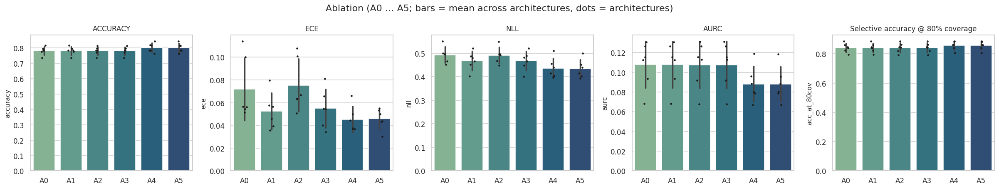

[saved figure] figures/F34_explanation_coverage_curves.png


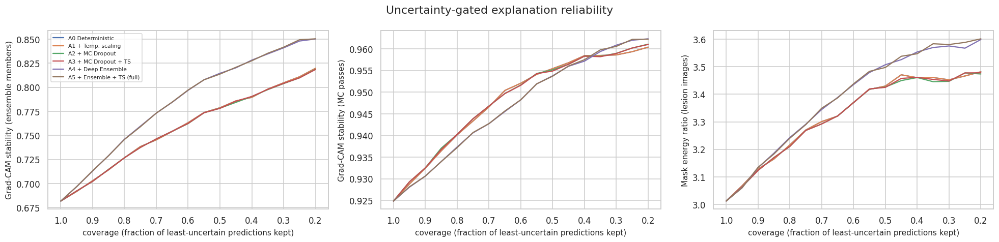

In [20]:
ABL = [('A0 Deterministic', 'Deterministic'), ('A1 + Temp. scaling', 'Deterministic + TS'), ('A2 + MC Dropout', 'MC Dropout'),
       ('A3 + MC Dropout + TS', 'MC Dropout + TS'), ('A4 + Deep Ensemble', 'Deep Ensemble'), ('A5 + Ensemble + TS (full)', 'Deep Ensemble + TS')]
ABL_NAMES = [a for a, _ in ABL]
rows, curves = [], []
for a in ARCHS:
    d = EXP[EXP.arch == a].sort_values('idx'); stab_e, stab_m, loc = d.stab_ens.values, d.stab_mc.values, d.loc_energy_ratio.values
    for nm, v in ABL:
        Ps = PR[a]['test'][v]; pm = Ps.mean(0); u = uncertainty(Ps)['entropy']; err = (pm.argmax(1) != yte_np).astype(float); N = len(err)
        o = np.argsort(u, kind='stable'); k = int(round(.8 * N)); acc_i, rej_i = o[:k], o[k:]
        rows.append(dict(architecture=a, config=nm, accuracy=1 - err.mean(), ece=ece_score(pm, yte_np), nll=nll_score(pm, yte_np), brier=brier_score(pm, yte_np),
                         aurc=aurc(u, err), acc_at_80cov=sel_acc(u, err, .8), err_detect_auroc=roc_auc_score(err, u) if 0 < err.sum() < N else np.nan,
                         stab_gap_ens=np.nanmean(stab_e[acc_i]) - np.nanmean(stab_e[rej_i]), stab_gap_mc=np.nanmean(stab_m[acc_i]) - np.nanmean(stab_m[rej_i]),
                         loc_gap=np.nanmean(loc[acc_i]) - np.nanmean(loc[rej_i])))
        for c in np.linspace(.2, 1, 17):
            s = o[:int(round(c * N))]
            curves.append(dict(architecture=a, config=nm, coverage=c, stab_ens=np.nanmean(stab_e[s]), stab_mc=np.nanmean(stab_m[s]), loc=np.nanmean(loc[s]) if np.isfinite(loc[s]).any() else np.nan))
AB = pd.DataFrame(rows); CV = pd.DataFrame(curves)
save_table(AB, 'T15_ablation_per_architecture', index=False, show=False, png=False)
mets = ['accuracy', 'ece', 'nll', 'brier', 'aurc', 'acc_at_80cov', 'err_detect_auroc', 'stab_gap_ens', 'stab_gap_mc', 'loc_gap']
mm, ss = AB.groupby('config')[mets].mean().loc[ABL_NAMES], AB.groupby('config')[mets].std().loc[ABL_NAMES]
tab = mm.copy().astype(object)
for c in mets:
    tab[c] = [f'{m:.3f} ± {s:.3f}' for m, s in zip(mm[c], ss[c])]
print('=== Table 15 | ablation (mean ± std across architectures) ===')
save_table(tab, 'T15_ablation_mean_std')

fig, axs = plt.subplots(1, 5, figsize=(22, 4.2))
for ax, m in zip(axs, ['accuracy', 'ece', 'nll', 'aurc', 'acc_at_80cov']):
    sns.barplot(data=AB, x='config', y=m, order=ABL_NAMES, errorbar='sd', palette='crest', ax=ax); sns.stripplot(data=AB, x='config', y=m, order=ABL_NAMES, color='k', size=3, ax=ax)
    ax.set_title(m.upper() if m != 'acc_at_80cov' else 'Selective accuracy @ 80% coverage'); ax.set_xlabel(''); ax.set_xticklabels([n.split(' ')[0] for n in ABL_NAMES])
fig.suptitle('Ablation (A0 … A5; bars = mean across architectures, dots = architectures)'); savefig('F33_ablation_bars', fig)

fig, axs = plt.subplots(1, 3, figsize=(18, 4.4))
for ax, (m, t) in zip(axs, (('stab_ens', 'Grad-CAM stability (ensemble members)'), ('stab_mc', 'Grad-CAM stability (MC passes)'), ('loc', 'Mask energy ratio (lesion images)'))):
    for nm in ABL_NAMES:
        q = CV[CV.config == nm].groupby('coverage')[m].agg(['mean', 'std']); ax.plot(q.index, q['mean'], label=nm)
    ax.set_xlabel('coverage (fraction of least-uncertain predictions kept)'); ax.set_ylabel(t); ax.invert_xaxis()
axs[0].legend(fontsize=7); fig.suptitle('Uncertainty-gated explanation reliability'); savefig('F34_explanation_coverage_curves', fig)

fig, axs = plt.subplots(1, 3, figsize=(19, 4.3))
for ax, m in zip(axs, ('ece', 'aurc', 'stab_gap_ens')):
    sns.heatmap(AB.pivot(index='config', columns='architecture', values=m).loc[ABL_NAMES, ARCHS], annot=True, fmt='.3f', cmap='mako_r' if m != 'stab_gap_ens' else 'vlag', center=None if m != 'stab_gap_ens' else 0, ax=ax)
    ax.set_title(m); ax.set_xlabel(''); ax.set_ylabel(''); ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')
savefig('F35_ablation_heatmaps', fig)

## 11. Computational complexity
Parameters, FLOPs (1×3×224×224 forward, `torch.utils.flop_counter`), latency (batch 1 and 32), peak GPU memory and training time. The *effective* cost of uncertainty estimation is also shown: MC Dropout costs `T×` forward passes (reducible by caching backbone features since dropout sits in the head), deep ensembles cost `M×` forward passes and `M×` training.

=== Table 16 | computational complexity ===
[saved table] tables/T16_computational_complexity.csv


,params_M,GFLOPs,latency_ms_bs1,throughput_img_s_bs32,peak_mem_MB_bs32,train_sec_per_epoch,latency_MC_ms,latency_ensemble_ms,train_min_ensemble
architecture,,,,,,,,,
ResNet50,23.5121,8.1743,6.9147,344.6261,2272.4864,6.4625,207.4410,20.7441,3.6604
DenseNet121,6.9559,5.6663,17.2198,344.1910,2375.1844,8.2659,516.5953,51.6595,4.4008
EfficientNet-B0,4.0101,0.7691,8.9937,856.1208,2274.0593,6.8529,269.8119,26.9812,4.3154
MobileNetV3-Large,4.2046,0.4306,6.6846,1439.7808,2204.8389,5.7886,200.5367,20.0537,3.8673
ConvNeXt-Tiny,27.8217,8.9095,7.8342,232.0871,2299.2251,7.6836,235.0257,23.5026,4.2720
InceptionV3,21.7897,5.6718,11.1668,484.6739,2425.1648,6.8769,335.0035,33.5003,3.5511


[saved figure] figures/F36_complexity_bars.png


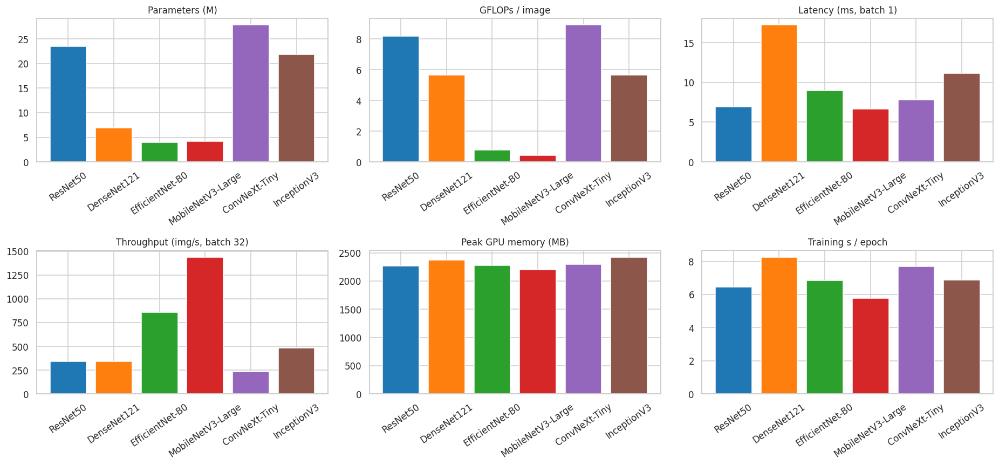

[saved figure] figures/F37_uncertainty_cost_and_tradeoff.png


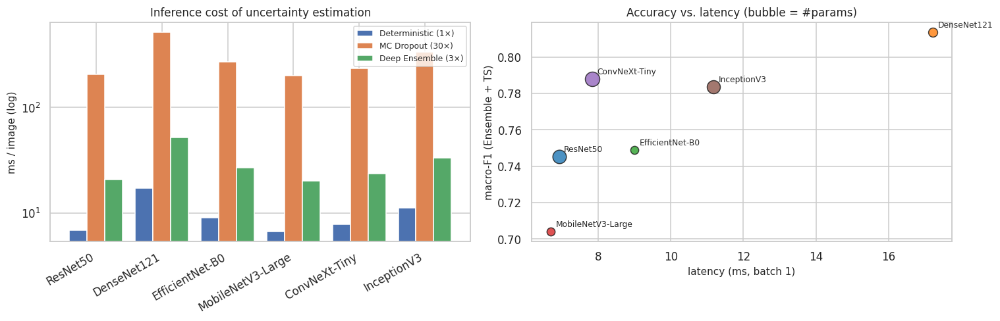

In [21]:
def measure(arch):
    m = MODELS[(arch, 0)].eval(); n_params = sum(p.numel() for p in m.parameters()) / 1e6
    x1, x32 = torch.rand(1, 3, CFG.IMG, CFG.IMG, device=device), torch.rand(32, 3, CFG.IMG, CFG.IMG, device=device)
    try:
        from torch.utils.flop_counter import FlopCounterMode
        with FlopCounterMode(display=False) as fc, torch.no_grad():
            m(x1)
        gflops = fc.get_total_flops() / 1e9
    except Exception:
        gflops = np.nan
    sync = (lambda: torch.cuda.synchronize()) if device.type == 'cuda' else (lambda: None)
    with torch.no_grad():
        for _ in range(10):
            m(x1)
        sync(); ts = []
        for _ in range(50):
            t0 = time.perf_counter(); m(x1); sync(); ts.append(time.perf_counter() - t0)
        if device.type == 'cuda':
            torch.cuda.reset_peak_memory_stats()
        for _ in range(3):
            m(x32)
        sync(); t0 = time.perf_counter()
        for _ in range(10):
            m(x32)
        sync(); thr = 320 / (time.perf_counter() - t0)
    mem = torch.cuda.max_memory_allocated() / 1e6 if device.type == 'cuda' else np.nan
    return dict(params_M=n_params, GFLOPs=gflops, latency_ms_bs1=1000 * np.median(ts), throughput_img_s_bs32=thr, peak_mem_MB_bs32=mem)


rows = []
for a in ARCHS:
    r = measure(a); r['architecture'] = a
    r['train_sec_per_epoch'] = np.mean([HIST[(a, s)].sec.mean() for s in range(CFG.ENS_M)])
    r['latency_MC_ms'] = r['latency_ms_bs1'] * CFG.MC_T; r['latency_ensemble_ms'] = r['latency_ms_bs1'] * CFG.ENS_M
    r['train_min_ensemble'] = np.sum([HIST[(a, s)].sec.sum() for s in range(CFG.ENS_M)]) / 60
    rows.append(r)
CX = pd.DataFrame(rows).set_index('architecture')
print('=== Table 16 | computational complexity ==='); save_table(CX, 'T16_computational_complexity')

fig, axs = plt.subplots(2, 3, figsize=(17, 8))
for ax, (c, t) in zip(axs.ravel(), (('params_M', 'Parameters (M)'), ('GFLOPs', 'GFLOPs / image'), ('latency_ms_bs1', 'Latency (ms, batch 1)'),
                                    ('throughput_img_s_bs32', 'Throughput (img/s, batch 32)'), ('peak_mem_MB_bs32', 'Peak GPU memory (MB)'), ('train_sec_per_epoch', 'Training s / epoch'))):
    ax.bar(ARCHS, CX.loc[ARCHS, c], color=[PAL[a] for a in ARCHS]); ax.set_title(t); ax.tick_params(axis='x', rotation=35)
savefig('F36_complexity_bars', fig)

fig, axs = plt.subplots(1, 2, figsize=(14, 4.6)); w_ = .27; x_ = np.arange(len(ARCHS))
axs[0].bar(x_ - w_, CX.loc[ARCHS, 'latency_ms_bs1'], w_, label='Deterministic (1×)'); axs[0].bar(x_, CX.loc[ARCHS, 'latency_MC_ms'], w_, label=f'MC Dropout ({CFG.MC_T}×)'); axs[0].bar(x_ + w_, CX.loc[ARCHS, 'latency_ensemble_ms'], w_, label=f'Deep Ensemble ({CFG.ENS_M}×)')
axs[0].set_yscale('log'); axs[0].set_xticks(x_); axs[0].set_xticklabels(ARCHS, rotation=30, ha='right'); axs[0].set_ylabel('ms / image (log)'); axs[0].set_title('Inference cost of uncertainty estimation'); axs[0].legend(fontsize=8)
for a in ARCHS:
    f1_ = T1[(T1.architecture == a) & (T1.variant == 'Deep Ensemble + TS')].f1.iloc[0]
    axs[1].scatter(CX.loc[a, 'latency_ms_bs1'], f1_, s=40 + 6 * CX.loc[a, 'params_M'], color=PAL[a], alpha=.8, edgecolor='k'); axs[1].annotate(a, (CX.loc[a, 'latency_ms_bs1'], f1_), fontsize=8, xytext=(5, 5), textcoords='offset points')
axs[1].set_xlabel('latency (ms, batch 1)'); axs[1].set_ylabel('macro-F1 (Ensemble + TS)'); axs[1].set_title('Accuracy vs. latency (bubble = #params)')
savefig('F37_uncertainty_cost_and_tradeoff', fig)

## 12. Final synthesis: does the most accurate architecture also give the most reliable and interpretable predictions?
Architectures are ranked (1 = best) on accuracy, calibration, uncertainty quality (AURC), explanation stability, lesion correspondence and robustness. The composite *reliability rank* excludes accuracy and cost.

=== Table 17 | summary of all criteria (Deep Ensemble + TS) ===
[saved table] tables/T17_final_summary.csv


,macro_F1,accuracy,ECE,NLL,AURC,err_detect_AUROC,stab_ens,stab_mc,loc_energy_ratio,loc_iou,robust_acc,GFLOPs,latency_ms,params_M
ResNet50,0.7452,0.7833,0.0532,0.4386,0.0885,0.7741,0.6415,0.9811,3.0997,0.1978,0.7363,8.1743,6.9147,23.5121
DenseNet121,0.8136,0.8433,0.0501,0.4029,0.0806,0.7158,0.6405,0.8731,2.2694,0.2335,0.7225,5.6663,17.2198,6.9559
EfficientNet-B0,0.7488,0.7833,0.0437,0.4525,0.0959,0.7576,0.7406,0.9561,3.4730,0.3119,0.6860,0.7691,8.9937,4.0101
MobileNetV3-Large,0.7041,0.7624,0.0551,0.4990,0.1185,0.7196,0.7874,0.9776,3.4084,0.2840,0.7314,0.4306,6.6846,4.2046
ConvNeXt-Tiny,0.7879,0.8146,0.0302,0.3939,0.0670,0.7936,0.6398,0.9269,4.0601,0.2571,0.7909,8.9095,7.8342,27.8217
InceptionV3,0.7836,0.8172,0.0433,0.4150,0.0789,0.7519,0.6411,0.8345,1.7665,0.1746,0.6451,5.6718,11.1668,21.7897


=== Table 18 | ranks (1 = best) ===
[saved table] tables/T18_rankings.csv


,Accuracy (F1),Calibration (ECE),Uncertainty (AURC),Expl. stability,Lesion correspondence,Robustness,Composite reliability rank,Overall rank (reliability)
ConvNeXt-Tiny,2.0,1.0,1.0,5.0,1.0,1.0,1.8,1.0
ResNet50,5.0,5.0,4.0,2.0,4.0,2.0,3.4,2.0
EfficientNet-B0,4.0,3.0,5.0,2.5,2.0,5.0,3.5,3.0
MobileNetV3-Large,6.0,6.0,6.0,1.5,3.0,3.0,3.9,4.0
DenseNet121,1.0,4.0,3.0,5.0,5.0,4.0,4.2,5.0
InceptionV3,3.0,2.0,2.0,5.0,6.0,6.0,4.2,5.0


[saved figure] figures/F38_final_rankings.png


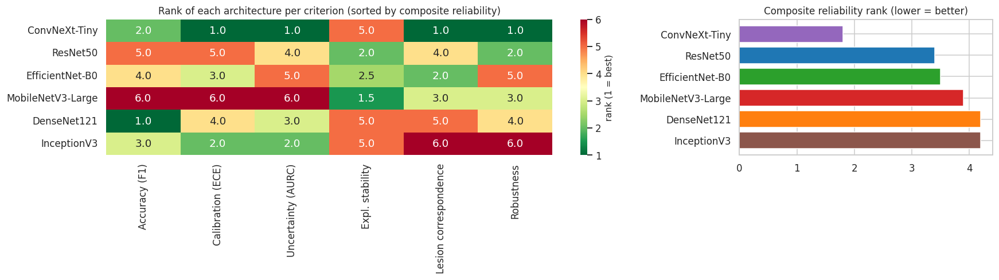

Highest macro-F1 (Ensemble+TS): DenseNet121  (F1=0.814)
Best composite reliability rank:  ConvNeXt-Tiny
The most accurate architecture is NOT the most reliable one (accuracy ≠ trustworthiness).
Spearman(accuracy rank, composite reliability rank) = -0.20 (p=0.70, n=6 architectures; interpret with caution)
Pooled Spearman(entropy_ens, stab_mc) = -0.47 [-0.50, -0.44], p=1.19e-127
Pooled Spearman(entropy_ens, stab_ens) = -0.62 [-0.64, -0.59], p=3.12e-240


454

In [22]:
fin = pd.DataFrame(index=ARCHS)
e = T1[T1.variant == 'Deep Ensemble + TS'].set_index('architecture')
fin['macro_F1'] = e.f1; fin['accuracy'] = e.accuracy; fin['ECE'] = e.ece; fin['NLL'] = e.nll
fin['AURC'] = T5[(T5.variant == 'Deep Ensemble + TS') & (T5.measure == 'entropy')].set_index('architecture').aurc
fin['err_detect_AUROC'] = T4[(T4.variant == 'Deep Ensemble + TS') & (T4.measure == 'entropy')].set_index('architecture').auroc_error_detection
fin['stab_ens'] = EXP.groupby('arch').stab_ens.mean(); fin['stab_mc'] = EXP.groupby('arch').stab_mc.mean()
fin['loc_energy_ratio'] = EXP.groupby('arch').loc_energy_ratio.mean(); fin['loc_iou'] = EXP.groupby('arch').loc_iou.mean()
fin['robust_acc'] = ROB[(ROB.variant == 'Deep Ensemble + TS') & (ROB.level > 0)].groupby('architecture').acc.mean()
fin['GFLOPs'] = CX.GFLOPs; fin['latency_ms'] = CX.latency_ms_bs1; fin['params_M'] = CX.params_M
print('=== Table 17 | summary of all criteria (Deep Ensemble + TS) ==='); save_table(fin, 'T17_final_summary')

rk = pd.DataFrame(index=ARCHS)
rk['Accuracy (F1)'] = fin.macro_F1.rank(ascending=False, method='min'); rk['Calibration (ECE)'] = fin.ECE.rank(method='min'); rk['Uncertainty (AURC)'] = fin.AURC.rank(method='min')
rk['Expl. stability'] = (fin.stab_ens.rank(ascending=False) + fin.stab_mc.rank(ascending=False)).div(2); rk['Lesion correspondence'] = fin.loc_energy_ratio.rank(ascending=False, method='min')
rk['Robustness'] = fin.robust_acc.rank(ascending=False, method='min')
rel_cols = ['Calibration (ECE)', 'Uncertainty (AURC)', 'Expl. stability', 'Lesion correspondence', 'Robustness']
rk['Composite reliability rank'] = rk[rel_cols].mean(1); rk['Overall rank (reliability)'] = rk['Composite reliability rank'].rank(method='min')
print('=== Table 18 | ranks (1 = best) ==='); save_table(rk.sort_values('Composite reliability rank'), 'T18_rankings')

fig, axs = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw=dict(width_ratios=[2.2, 1]))
sns.heatmap(rk[['Accuracy (F1)'] + rel_cols].loc[rk.sort_values('Composite reliability rank').index], annot=True, fmt='.1f', cmap='RdYlGn_r', ax=axs[0], cbar_kws=dict(label='rank (1 = best)'))
axs[0].set_title('Rank of each architecture per criterion (sorted by composite reliability)')
q = rk['Composite reliability rank'].sort_values(); axs[1].barh(q.index, q.values, color=[PAL[a] for a in q.index]); axs[1].invert_yaxis(); axs[1].set_title('Composite reliability rank (lower = better)')
savefig('F38_final_rankings', fig)

best_acc, best_rel = rk['Accuracy (F1)'].idxmin(), rk['Composite reliability rank'].idxmin()
rho_ar = stats.spearmanr(rk['Accuracy (F1)'], rk['Composite reliability rank'])
msg = [f'Highest macro-F1 (Ensemble+TS): {best_acc}  (F1={fin.macro_F1[best_acc]:.3f})',
       f'Best composite reliability rank:  {best_rel}',
       'The most accurate architecture IS also the most reliable one.' if best_acc == best_rel else 'The most accurate architecture is NOT the most reliable one (accuracy ≠ trustworthiness).',
       f'Spearman(accuracy rank, composite reliability rank) = {rho_ar[0]:.2f} (p={rho_ar[1]:.2f}, n={len(ARCHS)} architectures; interpret with caution)']
pool = T10[(T10.group == 'Pooled') & (T10.uncertainty == 'entropy_ens') & (T10.explanation_metric.isin(['stab_ens', 'stab_mc']))]
for _, r in pool.iterrows():
    msg.append(f'Pooled Spearman(entropy_ens, {r.explanation_metric}) = {r.rho:.2f} [{r.lo:.2f}, {r.hi:.2f}], p={r.p:.3g}')
print('\n'.join(msg))
json.dump(dict(findings=msg, best_arch_validation=BEST_ARCH), open(OUT / 'summary.json', 'w'), indent=2)
(OUT / 'key_findings.txt').write_text('\n'.join(msg))

## 13. Package everything
`/content/BUSBRA_UQ_XAI_results/` holds only the manuscript-relevant figures (PNG, 300 dpi) and tables (CSV) and is zipped for download. Checkpoints, logits and long tables stay in `/content/work_busbra/`.

In [23]:
man = pd.DataFrame([dict(file=str(p.relative_to(OUT)), size_kb=round(p.stat().st_size / 1024, 1)) for p in sorted(OUT.rglob('*')) if p.is_file()])
man.to_csv(OUT / 'MANIFEST.csv', index=False)
print(f"figures: {len(list(FIG.glob('*.png')))} | tables: {len(list(TAB.glob('*.csv')))} | total files: {len(man)}")
display(man.groupby(man.file.str.split('/').str[0]).agg(files=('file', 'count'), size_MB=('size_kb', lambda s: round(s.sum() / 1024, 1))))
zip_path = shutil.make_archive('/content/' + OUT.name, 'zip', OUT)
print('zip:', zip_path)
if CFG.SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive'); shutil.copytree(OUT, CFG.DRIVE_DIR, dirs_exist_ok=True); print('copied to', CFG.DRIVE_DIR)
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    pass

figures: 30 | tables: 20 | total files: 53


,files,size_MB
file,,
config_and_env.json,1,0.0
figures,30,39.4
key_findings.txt,1,0.0
summary.json,1,0.0
tables,20,0.3


zip: /content/BUSBRA_UQ_XAI_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>